<a href="https://colab.research.google.com/github/Ben-069/DataManPy/blob/main/NBIPAR_Dengean%26Ortega.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#DETERMINANTS OF NBI IN RURAL PARAGUAY - Evidence of 2022 Data
**Authors:** Benito Ortega Torres M.Sc ; Rosa Marilin Dengean Paiva M.Sc
**Class:** Data Management, fall 2026
**Professor:** Adam Okulicz-Kozaryn, Phd

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
sociopy2022 = pd.ExcelFile("https://docs.google.com/uc?id=1Vl1isMiaQTvlwIu8yN4hk3X8dcXTEDDh&export=download")
agrcensus2022= pd.ExcelFile("https://docs.google.com/uc?id=1n8d_1lubOtPqiwjadoadYDMWuLBaI__b&export=download")

In [ ]:
print("Hojas del archivo 1:", sociopy2022.sheet_names)
print("Hojas del archivo 2:", agrcensus2022.sheet_names)

Hojas del archivo 1: ['Cuadro 1', 'Cuadro 2', 'Cuadro 3', 'Cuadro 4']
Hojas del archivo 2: ['PEDIDO']


##2022 NBI NATIONAL INSTIUTE OF STATISTICS DATA

In [ ]:
sociopy2022 = pd.read_excel("https://docs.google.com/uc?id=1Vl1isMiaQTvlwIu8yN4hk3X8dcXTEDDh&export=download",sheet_name="Cuadro 4",header=None)

agrcensus2022 = pd.read_excel("https://docs.google.com/uc?id=1n8d_1lubOtPqiwjadoadYDMWuLBaI__b&export=download",sheet_name="PEDIDO",header=None)

In [ ]:
sociopy2022.head(16)

,0,1,2,3,4,5,6,7
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,Cuadro 4,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,Paraguay. Hogares particulares por Necesidades...,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,Departamento y distrito,Total de hogares,Hogares con Necesidades Básicas Insatisfechas ...,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,Al menos una NBI,NBI en,NaN,NaN,NaN


In [ ]:
"Dimensiones de NBI:", sociopy2022.shape
"Dimensiones de CAN:", agrcensus2022.shape

('Dimensiones de CAN:', (311, 17))

In [ ]:
nbi = sociopy2022.iloc[12:, 1:8].copy()
nbi.columns = ["name","total_homes","homeswithonenbi","homesnbihouse","homesnbisanity","homesnbieduc","homesnbisubs"]
display(nbi.head(10))

,name,total_homes,homeswithonenbi,homesnbihouse,homesnbisanity,homesnbieduc,homesnbisubs
12,Total País,1770755,501781,113025,184957,186865,147132
13,Asunción,133600,23296,5789,7383,6623,6746
14,Concepción,56837,19484,4635,7093,7269,6352
15,Concepción,19196,5678,1603,1999,1797,1575
16,Belén,3015,963,228,252,357,341
17,Horqueta,11355,3409,700,878,1427,1242
18,Loreto,3811,1261,283,473,409,412
19,San Carlos del Apa,270,129,31,49,43,30
20,San Lázaro,3068,1347,389,811,426,229
21,Yby Yaú,5561,2150,499,840,1043,723


In [ ]:
nbi.tail(10)

,name,total_homes,homeswithonenbi,homesnbihouse,homesnbisanity,homesnbieduc,homesnbisubs
284,Mariscal José Félix Estigarribia,3412,2356,688,1758,884,1036
285,Filadelfia,6096,5006,547,4715,1038,562
286,Loma Plata,6257,5764,564,5642,860,638
287,Boquerón,4633,3971,726,3677,863,766
288,Alto Paraguay,5199,3272,802,2280,1028,853
289,Fuerte Olimpo,1320,800,213,558,230,169
290,Puerto Casado,1689,1152,281,918,352,349
291,Bahía Negra,850,514,129,323,182,97
292,Carmelo Peralta,1340,806,179,481,264,238
293,Fuente: INE. Censo Nacional de Población y Viv...,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print("before:", len(nbi))
nbi = nbi.dropna(subset=["total_homes"]).copy()
print("after:", len(nbi))
display(nbi.tail(5))

before: 282
after: 281


,name,total_homes,homeswithonenbi,homesnbihouse,homesnbisanity,homesnbieduc,homesnbisubs
288,Alto Paraguay,5199,3272,802,2280,1028,853
289,Fuerte Olimpo,1320,800,213,558,230,169
290,Puerto Casado,1689,1152,281,918,352,349
291,Bahía Negra,850,514,129,323,182,97
292,Carmelo Peralta,1340,806,179,481,264,238


In [ ]:
import openpyxl
import requests
import io
#code suggested by gemini ai
# Download the file content from the URL
url = "https://docs.google.com/uc?id=1Vl1isMiaQTvlwIu8yN4hk3X8dcXTEDDh&export=download"
response = requests.get(url)

# Load the workbook from the in-memory bytes object
libro = openpyxl.load_workbook(io.BytesIO(response.content), data_only=True)
hoja = libro["Cuadro 4"]

nbi["bold_name"] = [
    hoja.cell(row=indice + 1, column=2).font.bold == True
    for indice in nbi.index
    ]

display(nbi[["name", "total_homes", "bold_name"]].head(20))

,name,total_homes,bold_name
12,Total País,1770755,True
13,Asunción,133600,True
14,Concepción,56837,True
15,Concepción,19196,False
16,Belén,3015,False
17,Horqueta,11355,False
18,Loreto,3811,False
19,San Carlos del Apa,270,False
20,San Lázaro,3068,False
21,Yby Yaú,5561,False


In [ ]:
nbi["department"] = nbi["name"].where(nbi["bold_name"])

nbi["department"] = nbi["department"].ffill()

display(nbi[["name", "department", "bold_name"]].head(20))

,name,department,bold_name
12,Total País,Total País,True
13,Asunción,Asunción,True
14,Concepción,Concepción,True
15,Concepción,Concepción,False
16,Belén,Concepción,False
17,Horqueta,Concepción,False
18,Loreto,Concepción,False
19,San Carlos del Apa,Concepción,False
20,San Lázaro,Concepción,False
21,Yby Yaú,Concepción,False


In [ ]:
es_distrito = nbi["bold_name"] == False
es_asuncion = nbi["name"] == "Asunción"

nbi_districts = nbi[es_distrito | es_asuncion].copy()

nbi_districts = nbi_districts.rename(columns={"name": "district"})

print("row before getting rid of the departament totals:", len(nbi))
print("Municipalities units:", len(nbi_districts))

display(
    nbi_districts[["department", "district", "total_homes"]].head(10)
)

row before getting rid of the departament totals: 281
Municipalities units: 263


,department,district,total_homes
13,Asunción,Asunción,133600
15,Concepción,Concepción,19196
16,Concepción,Belén,3015
17,Concepción,Horqueta,11355
18,Concepción,Loreto,3811
19,Concepción,San Carlos del Apa,270
20,Concepción,San Lázaro,3068
21,Concepción,Yby Yaú,5561
22,Concepción,Azote’y,1821
23,Concepción,Sargento José Félix López,1656


In [ ]:
duplicados = nbi_districts.duplicated(subset=["department", "district"], keep=False)
print("rows with duplicates departaments and municipalities:", duplicados.sum())

display(nbi_districts.loc[duplicados, ["department", "district"]])

rows with duplicates departaments and municipalities: 0


,department,district


In [ ]:
numeric_columns = ["total_homes","homeswithonenbi","homesnbihouse","homesnbisanity","homesnbieduc","homesnbisubs"]
for column in numeric_columns:nbi_districts[column] = pd.to_numeric(nbi_districts[column],errors="raise")
nbi_districts[numeric_columns].dtypes



,0
total_homes,int64
homeswithonenbi,int64
homesnbihouse,int64
homesnbisanity,int64
homesnbieduc,int64
homesnbisubs,int64


In [ ]:
print("missing values per column:")
nbi_districts[numeric_columns].isna().sum()


missing values per column:


,0
total_homes,0
homeswithonenbi,0
homesnbihouse,0
homesnbisanity,0
homesnbieduc,0
homesnbisubs,0


In [ ]:
print("type of data:")
nbi_districts[numeric_columns].dtypes

type of data:


,0
total_homes,int64
homeswithonenbi,int64
homesnbihouse,int64
homesnbisanity,int64
homesnbieduc,int64
homesnbisubs,int64


In [ ]:
print("Unidades con total de hogares menor o igual a cero:",(nbi_districts["total_homes"] <= 0).sum()
)

for column in numeric_columns[1:]:
    invalid = ((nbi_districts[column] < 0)| (nbi_districts[column] > nbi_districts["total_homes"]))

    print(column, "— valores fuera del rango:", invalid.sum())

Unidades con total de hogares menor o igual a cero: 0
homeswithonenbi — valores fuera del rango: 0
homesnbihouse — valores fuera del rango: 0
homesnbisanity — valores fuera del rango: 0
homesnbieduc — valores fuera del rango: 0
homesnbisubs — valores fuera del rango: 0


In [ ]:
nbi_districts["nbi_subsistence_pct"] = (nbi_districts["homesnbisubs"]/ nbi_districts["total_homes"]) * 100
nbi_districts[["department","district","total_homes","homesnbisubs","nbi_subsistence_pct"]].head(10)

,department,district,total_homes,homesnbisubs,nbi_subsistence_pct
13,Asunción,Asunción,133600,6746,5.049401
15,Concepción,Concepción,19196,1575,8.204834
16,Concepción,Belén,3015,341,11.310116
17,Concepción,Horqueta,11355,1242,10.937913
18,Concepción,Loreto,3811,412,10.810811
19,Concepción,San Carlos del Apa,270,30,11.111111
20,Concepción,San Lázaro,3068,229,7.464146
21,Concepción,Yby Yaú,5561,723,13.001259
22,Concepción,Azote’y,1821,328,18.012081
23,Concepción,Sargento José Félix López,1656,224,13.526570


In [ ]:
print("pct out of range 0 a 100:",(~nbi_districts["nbi_subsistence_pct"].between(0, 100)).sum())

pct out of range 0 a 100: 0


In [ ]:
duplicate_count = nbi_districts.duplicated(subset=["department", "district"]).sum()
print("duplicated combinations:", duplicate_count)

duplicated combinations: 0


In [ ]:
#nbi_districts.to_csv("NBI_districts_2022.csv",index=False,encoding="utf-8-sig")

## SOCIO DEMOGRAPHIC DATA - INE

In [ ]:
household_var2022 = pd.read_excel("https://docs.google.com/uc?id=1Vl1isMiaQTvlwIu8yN4hk3X8dcXTEDDh&export=download",sheet_name="Cuadro 1",header=None)
household_var2022.head(10)

,0,1,2,3,4,5,6,7
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,Cuadro 1,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,Paraguay. Hogares particulares por tipo de hog...,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,Departamento y distrito,Total de hogares,Tipo de Hogar,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,Unipersonal,Nuclear completo,Nuclear incompleto,Extendido,Compuesto


In [ ]:
"Dimensiones de Composición Familiar:", household_var2022.shape

('Dimensiones de Composición Familiar:', (293, 8))

In [ ]:
fam_type = household_var2022.iloc[12:, 1:8].copy()
fam_type.columns = ["name","total_homes","uni_home","comp_home","incomp_home","ext_home","compound_home"]
fam_type.head(10)

,name,total_homes,uni_home,comp_home,incomp_home,ext_home,compound_home
12,Asunción,133600,24372,48768,14652,40834,4974
13,Concepción,56837,7638,24617,7133,16401,1048
14,Concepción,19196,2438,7567,2345,6363,483
15,Belén,3015,405,1374,365,840,31
16,Horqueta,11355,1599,5204,1404,3019,129
17,Loreto,3811,468,1764,505,1044,30
18,San Carlos del Apa,270,60,120,29,56,5
19,San Lázaro,3068,470,1317,321,901,59
20,Yby Yaú,5561,727,2540,698,1484,112
21,Azote’y,1821,237,820,277,461,26


In [ ]:
fam_type.tail(3)


,name,total_homes,uni_home,comp_home,incomp_home,ext_home,compound_home
290,Bahía Negra,850,175,346,82,155,92
291,Carmelo Peralta,1340,238,546,216,281,59
292,Fuente: INE. Censo Nacional de Población y Viv...,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
fam_type = fam_type.dropna(subset=["total_homes"]).copy()
household_sheet = libro["Cuadro 1"]
fam_type["bold_name"] = [household_sheet.cell(row=index + 1, column=2 ).font.bold == True for index in fam_type.index]


In [ ]:
fam_type[["name", "total_homes", "bold_name"]].head(16)

,name,total_homes,bold_name
12,Asunción,133600,True
13,Concepción,56837,True
14,Concepción,19196,False
15,Belén,3015,False
16,Horqueta,11355,False
17,Loreto,3811,False
18,San Carlos del Apa,270,False
19,San Lázaro,3068,False
20,Yby Yaú,5561,False
21,Azote’y,1821,False


In [ ]:
fam_type["department"] = fam_type["name"].where(fam_type["bold_name"])
fam_type["department"] = fam_type["department"].ffill()
is_district = ~fam_type["bold_name"]
is_asuncion = fam_type["name"] == "Asunción"
fam_districts = fam_type.loc[is_district | is_asuncion].copy()
fam_districts = fam_districts.rename(columns={"name": "district"})
print("Unidades distritales:", len(fam_districts))
print("Distritos sin departamento:",fam_districts["department"].isna().sum())
print("Combinaciones duplicadas:",fam_districts.duplicated(subset=["department", "district"]).sum())

Unidades distritales: 263
Distritos sin departamento: 0
Combinaciones duplicadas: 0


In [ ]:
fam_districts[["department", "district", "total_homes"]].head(10)

,department,district,total_homes
12,Asunción,Asunción,133600
14,Concepción,Concepción,19196
15,Concepción,Belén,3015
16,Concepción,Horqueta,11355
17,Concepción,Loreto,3811
18,Concepción,San Carlos del Apa,270
19,Concepción,San Lázaro,3068
20,Concepción,Yby Yaú,5561
21,Concepción,Azote’y,1821
22,Concepción,Sargento José Félix López,1656


In [ ]:
family_columns = ["uni_home","comp_home","incomp_home","ext_home","compound_home"]
for column in ["total_homes"] + family_columns:fam_districts[column] = pd.to_numeric(fam_districts[column],errors="raise")
#print("Missing values:")
fam_districts[["total_homes"] + family_columns].isna().sum()

,0
total_homes,0
uni_home,0
comp_home,0
incomp_home,0
ext_home,0
compound_home,0


In [ ]:
family_pct_columns = []
for column in family_columns:new_column = "pct_" + column
fam_districts[new_column] = (fam_districts[column]/ fam_districts["total_homes"]) * 100
family_pct_columns.append(new_column)
fam_districts[["department", "district"] + family_pct_columns].head(10)

,department,district,pct_compound_home
12,Asunción,Asunción,3.723054
14,Concepción,Concepción,2.516149
15,Concepción,Belén,1.028192
16,Concepción,Horqueta,1.136063
17,Concepción,Loreto,0.787195
18,Concepción,San Carlos del Apa,1.851852
19,Concepción,San Lázaro,1.923077
20,Concepción,Yby Yaú,2.014026
21,Concepción,Azote’y,1.427787
22,Concepción,Sargento José Félix López,2.717391


In [ ]:
import unicodedata

def normalize_name(text):
    text = text.lower().strip()
    text = text.replace("’", "'")
    text = text.replace("‘", "'")
    text = unicodedata.normalize("NFKD", text)
    text = "".join(
        character for character in text
        if not unicodedata.combining(character)
    )
    text = " ".join(text.split())
    return text

fam_districts["department_key"] = (fam_districts["department"].apply(normalize_name))
fam_districts["district_key"] = (fam_districts["district"].apply(normalize_name))
fam_districts.duplicated(subset=["department_key", "district_key"]).sum()

np.int64(0)

In [ ]:
fam_districts.head(10)

,district,total_homes,uni_home,comp_home,incomp_home,ext_home,compound_home,bold_name,department,pct_compound_home,department_key,district_key
12,Asunción,133600,24372,48768,14652,40834,4974,True,Asunción,3.723054,asuncion,asuncion
14,Concepción,19196,2438,7567,2345,6363,483,False,Concepción,2.516149,concepcion,concepcion
15,Belén,3015,405,1374,365,840,31,False,Concepción,1.028192,concepcion,belen
16,Horqueta,11355,1599,5204,1404,3019,129,False,Concepción,1.136063,concepcion,horqueta
17,Loreto,3811,468,1764,505,1044,30,False,Concepción,0.787195,concepcion,loreto
18,San Carlos del Apa,270,60,120,29,56,5,False,Concepción,1.851852,concepcion,san carlos del apa
19,San Lázaro,3068,470,1317,321,901,59,False,Concepción,1.923077,concepcion,san lazaro
20,Yby Yaú,5561,727,2540,698,1484,112,False,Concepción,2.014026,concepcion,yby yau
21,Azote’y,1821,237,820,277,461,26,False,Concepción,1.427787,concepcion,azote'y
22,Sargento José Félix López,1656,237,822,187,365,45,False,Concepción,2.717391,concepcion,sargento jose felix lopez


In [ ]:
keys = ["department_key", "district_key"]

family_to_merge = fam_districts[
    keys
    + ["total_homes"]
    + family_columns
    + family_pct_columns
].copy()

family_to_merge = family_to_merge.rename(
    columns={"total_homes": "total_homes_family"}
)

print(
    "Claves familiares duplicadas:",
    family_to_merge.duplicated(subset=keys).sum()
)

Claves familiares duplicadas: 0


In [ ]:
family_to_merge.head(10)

,department_key,district_key,total_homes_family,uni_home,comp_home,incomp_home,ext_home,compound_home,pct_compound_home
12,asuncion,asuncion,133600,24372,48768,14652,40834,4974,3.723054
14,concepcion,concepcion,19196,2438,7567,2345,6363,483,2.516149
15,concepcion,belen,3015,405,1374,365,840,31,1.028192
16,concepcion,horqueta,11355,1599,5204,1404,3019,129,1.136063
17,concepcion,loreto,3811,468,1764,505,1044,30,0.787195
18,concepcion,san carlos del apa,270,60,120,29,56,5,1.851852
19,concepcion,san lazaro,3068,470,1317,321,901,59,1.923077
20,concepcion,yby yau,5561,727,2540,698,1484,112,2.014026
21,concepcion,azote'y,1821,237,820,277,461,26,1.427787
22,concepcion,sargento jose felix lopez,1656,237,822,187,365,45,2.717391


In [ ]:
# Define 'analysis' if it hasn't been defined yet, using nbi_districts as the base
if 'analysis' not in globals():
    analysis = nbi_districts.copy()

# Ensure the merge keys exist in 'analysis'
if "department_key" not in analysis.columns:
    analysis["department_key"] = analysis["department"].apply(normalize_name)
if "district_key" not in analysis.columns:
    analysis["district_key"] = analysis["district"].apply(normalize_name)

analysis_family = analysis.merge(family_to_merge, on=keys, how="left", validate="one_to_one", indicator="family_match")
display(analysis_family["family_match"].value_counts().to_frame("units"))

,units
family_match,
both,263
left_only,0
right_only,0


In [ ]:
analysis_family.head(20)

,district,total_homes,homeswithonenbi,homesnbihouse,homesnbisanity,homesnbieduc,homesnbisubs,bold_name,department,nbi_subsistence_pct,department_key,district_key,total_homes_family,uni_home,comp_home,incomp_home,ext_home,compound_home,pct_compound_home,family_match
0,Asunción,133600,23296,5789,7383,6623,6746,True,Asunción,5.049401,asuncion,asuncion,133600,24372,48768,14652,40834,4974,3.723054,both
1,Concepción,19196,5678,1603,1999,1797,1575,False,Concepción,8.204834,concepcion,concepcion,19196,2438,7567,2345,6363,483,2.516149,both
2,Belén,3015,963,228,252,357,341,False,Concepción,11.310116,concepcion,belen,3015,405,1374,365,840,31,1.028192,both
3,Horqueta,11355,3409,700,878,1427,1242,False,Concepción,10.937913,concepcion,horqueta,11355,1599,5204,1404,3019,129,1.136063,both
4,Loreto,3811,1261,283,473,409,412,False,Concepción,10.810811,concepcion,loreto,3811,468,1764,505,1044,30,0.787195,both
5,San Carlos del Apa,270,129,31,49,43,30,False,Concepción,11.111111,concepcion,san carlos del apa,270,60,120,29,56,5,1.851852,both
6,San Lázaro,3068,1347,389,811,426,229,False,Concepción,7.464146,concepcion,san lazaro,3068,470,1317,321,901,59,1.923077,both
7,Yby Yaú,5561,2150,499,840,1043,723,False,Concepción,13.001259,concepcion,yby yau,5561,727,2540,698,1484,112,2.014026,both
8,Azote’y,1821,702,213,182,318,328,False,Concepción,18.012081,concepcion,azote'y,1821,237,820,277,461,26,1.427787,both
9,Sargento José Félix López,1656,787,175,404,301,224,False,Concepción,13.526570,concepcion,sargento jose felix lopez,1656,237,822,187,365,45,2.717391,both


In [ ]:
family_columns = [
    "uni_home",
    "comp_home",
    "incomp_home",
    "ext_home",
    "compound_home"
]

family_pct_columns = []

analysis_family["total_homes"] = pd.to_numeric(
    analysis_family["total_homes"],
    errors="raise"
)

for column in family_columns:
    analysis_family[column] = pd.to_numeric(
        analysis_family[column],
        errors="raise"
    )

    new_column = "pct_" + column

    analysis_family[new_column] = (
        analysis_family[column]
        / analysis_family["total_homes"]
    ) * 100

    family_pct_columns.append(new_column)

In [ ]:
print("Porcentajes creados:", len(family_pct_columns))

display(
    analysis_family[family_pct_columns].dtypes
)

family_descriptives = (
    analysis_family[family_pct_columns]
    .describe()
    .T
)

display(family_descriptives.round(2))

Porcentajes creados: 5


,0
pct_uni_home,float64
pct_comp_home,float64
pct_incomp_home,float64
pct_ext_home,float64
pct_compound_home,float64


,count,mean,std,min,25%,50%,75%,max
pct_uni_home,263.0,17.22,3.54,9.64,14.62,16.79,19.32,29.66
pct_comp_home,263.0,46.28,6.44,28.03,42.03,45.57,50.70,64.98
pct_incomp_home,263.0,11.23,1.72,5.72,10.30,11.28,12.17,19.68
pct_ext_home,263.0,23.42,4.35,10.14,20.51,23.41,26.67,34.34
pct_compound_home,263.0,1.86,1.51,0.51,1.17,1.56,2.07,18.38


In [ ]:
display(
    analysis_family[
        [
            "department",
            "district",
            "pct_compound_home",
            "nbi_subsistence_pct"
        ]
    ].nlargest(5, "pct_compound_home")
)

,department,district,pct_compound_home,nbi_subsistence_pct
251,Presidente Hayes,Teniente Esteban Martínez,18.383312,20.078227
261,Alto Paraguay,Bahía Negra,10.823529,11.411765
220,Ñeembucú,Villa Franca,8.630952,6.547619
259,Alto Paraguay,Fuerte Olimpo,6.212121,12.803030
252,Presidente Hayes,General José María Bruguez,5.941846,20.606827


In [ ]:
family_correlation_rows = []

for column in family_pct_columns:
    pair = analysis_family[
        ["nbi_subsistence_pct", column]
    ].dropna()

    family_correlation_rows.append([
        column,
        len(pair),
        pair["nbi_subsistence_pct"].corr(
            pair[column], method="pearson"
        ),
        pair["nbi_subsistence_pct"].corr(
            pair[column], method="spearman"
        )
    ])

family_correlations = pd.DataFrame(
    family_correlation_rows,
    columns=["variable", "n", "pearson_r", "spearman_rho"]
)

display(family_correlations.round(3))

,variable,n,pearson_r,spearman_rho
0,pct_uni_home,263,0.238,0.360
1,pct_comp_home,263,-0.170,-0.161
2,pct_incomp_home,263,0.312,0.315
3,pct_ext_home,263,-0.098,-0.087
4,pct_compound_home,263,0.093,-0.190


In [ ]:
print("Columnas de porcentajes familiares:")
print(family_pct_columns)

print("Número de filas de la tabla de correlaciones:")
print(len(family_correlations))

display(family_correlations.round(3))

Columnas de porcentajes familiares:
['pct_uni_home', 'pct_comp_home', 'pct_incomp_home', 'pct_ext_home', 'pct_compound_home']
Número de filas de la tabla de correlaciones:
5


,variable,n,pearson_r,spearman_rho
0,pct_uni_home,263,0.238,0.360
1,pct_comp_home,263,-0.170,-0.161
2,pct_incomp_home,263,0.312,0.315
3,pct_ext_home,263,-0.098,-0.087
4,pct_compound_home,263,0.093,-0.190


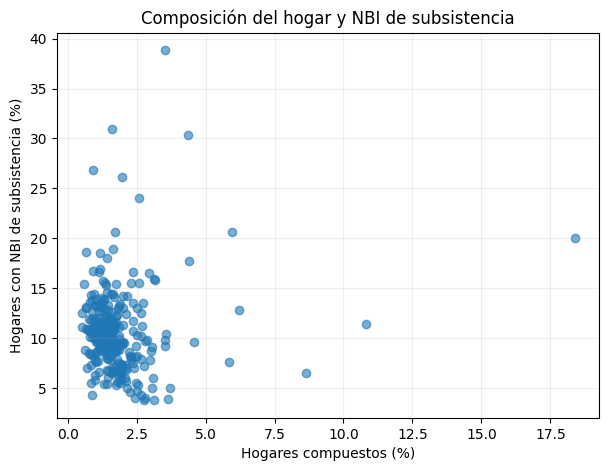

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(
    analysis_family["pct_compound_home"],
    analysis_family["nbi_subsistence_pct"],
    alpha=0.6
)

plt.xlabel("Hogares compuestos (%)")
plt.ylabel("Hogares con NBI de subsistencia (%)")
plt.title("Composición del hogar y NBI de subsistencia")
plt.grid(alpha=0.2)

plt.show()

## 2022 National Agronomic Census Data

In [ ]:
agrcensus2022.head(16)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,"Cuadro 1. Cantidad total de fincas, superficie...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Departamento / Distrito,Cantidad total de Fincas,Superficie total (ha),Tipo de actividad:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,Solo con actividad pecuaria,NaN,Solo plantaciones forestales,NaN,Con plantaciones forestales y actividad pecuaria,NaN,Solo con cultivos agrícolas,NaN,Con cultivos agricolas y actividad pecuaria,NaN,Con cultivos agricolas y plantaciones forestales,NaN,"Con cultivos agricolas, plantaciones forestale...",NaN
3,NaN,NaN,NaN,Cant. Fincas,Superficie (ha),Cant. Fincas,Superficie (ha),Cant. Fincas,Superficie (ha),Cant. Fincas,Superficie (ha),Cant. Fincas,Superficie (ha),Cant. Fincas,Superficie (ha),Cant. Fincas,Superficie (ha)
4,Total,291497,30401660.4529,73784,19223869.718,659,81716.723,2994,1238636.595,22758,1498315.525,181389,6189592.4229,1042,274638.649,8871,1894890.82
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Región Oriental,283052,13397506.4999,66943,4105260.965,655,76590.723,2945,856558.595,22268,1423750.225,180343,4832021.0229,1041,274635.149,8857,1828689.82
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,01. CONCEPCIÓN,16670,1521324.898,4966,960064.637,7,1588.5,62,169291.575,244,2946.6,11192,293623.636,6,994,193,92815.95
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
for column in agrcensus2022.columns:
    print("Columna:", column)
    print(agrcensus2022[column].iloc[:4].tolist())
    print()

Columna: 0
['Cuadro 1. Cantidad total de fincas, superficie total (ha), y Cantidad total de fincas y superficie (ha) por tipo de actividad , según departamentos y distritos. CAN 2022.', 'Departamento / Distrito', nan, nan]

Columna: 1
[nan, 'Cantidad  total de Fincas', nan, nan]

Columna: 2
[nan, 'Superficie total (ha)', nan, nan]

Columna: 3
[nan, 'Tipo de actividad:', 'Solo con actividad pecuaria', 'Cant. Fincas']

Columna: 4
[nan, nan, nan, 'Superficie (ha)']

Columna: 5
[nan, nan, ' Solo plantaciones forestales', 'Cant. Fincas']

Columna: 6
[nan, nan, nan, 'Superficie (ha)']

Columna: 7
[nan, nan, 'Con plantaciones forestales y actividad pecuaria', 'Cant. Fincas']

Columna: 8
[nan, nan, nan, 'Superficie (ha)']

Columna: 9
[nan, nan, 'Solo con cultivos agrícolas', 'Cant. Fincas']

Columna: 10
[nan, nan, nan, 'Superficie (ha)']

Columna: 11
[nan, nan, 'Con cultivos agricolas y actividad pecuaria', 'Cant. Fincas']

Columna: 12
[nan, nan, nan, 'Superficie (ha)']

Columna: 13
[nan, nan,

In [ ]:
can = agrcensus2022.iloc[6:].copy()
can.columns = ["name","farms_total","area_total_ha","farms_livestock_only","area_livestock_only_ha","farms_forestry_only","area_forestry_only_ha","farms_forestry_livestock","area_forestry_livestock_ha",
"farms_crops_only","area_crops_only_ha","farms_crops_livestock","area_crops_livestock_ha","farms_crops_forestry","area_crops_forestry_ha","farms_crops_forestry_livestock","area_crops_forestry_livestock_ha"]
can.head(5)

,name,farms_total,area_total_ha,farms_livestock_only,area_livestock_only_ha,farms_forestry_only,area_forestry_only_ha,farms_forestry_livestock,area_forestry_livestock_ha,farms_crops_only,area_crops_only_ha,farms_crops_livestock,area_crops_livestock_ha,farms_crops_forestry,area_crops_forestry_ha,farms_crops_forestry_livestock,area_crops_forestry_livestock_ha
6,Región Oriental,283052,13397506.4999,66943,4105260.965,655,76590.723,2945,856558.595,22268,1423750.225,180343,4832021.0229,1041,274635.149,8857,1828689.82
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,01. CONCEPCIÓN,16670,1521324.898,4966,960064.637,7,1588.5,62,169291.575,244,2946.6,11192,293623.636,6,994,193,92815.95
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,01. Concepción,1469,38210.259,397,11624.574,4,70.5,15,6527.0,20,331.15,1018,18950.035,2,38,13,669


In [ ]:
can.tail(5)

,name,farms_total,area_total_ha,farms_livestock_only,area_livestock_only_ha,farms_forestry_only,area_forestry_only_ha,farms_forestry_livestock,area_forestry_livestock_ha,farms_crops_only,area_crops_only_ha,farms_crops_livestock,area_crops_livestock_ha,farms_crops_forestry,area_crops_forestry_ha,farms_crops_forestry_livestock,area_crops_forestry_livestock_ha
306,01. Fuerte Olimpo,224,1474729.313,216,1346887.313,-,-,3,70753,-,-,5,57089,-,-,-,-
307,02. Puerto Casado,468,1633473.5,438,1441104.5,-,-,2,73657,4,2120,23,103925,-,-,1,12667
308,04. Bahía Negra,179,1366551.0,174,1301519.0,-,-,-,-,1,657,4,64375,-,-,-,-
309,05. Carmelo Peralta,186,398145.0,105,357383.0,-,-,1,633,-,-,76,2250.0,-,-,4,37879
310,"El valor ""0"" corresponde a cifras menores a 0.5",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
len(can)
can = can.dropna(how="all").copy()
can.tail(6)

,name,farms_total,area_total_ha,farms_livestock_only,area_livestock_only_ha,farms_forestry_only,area_forestry_only_ha,farms_forestry_livestock,area_forestry_livestock_ha,farms_crops_only,area_crops_only_ha,farms_crops_livestock,area_crops_livestock_ha,farms_crops_forestry,area_crops_forestry_ha,farms_crops_forestry_livestock,area_crops_forestry_livestock_ha
304,17. ALTO PARAGUAY,1057,4872898.813,933,4446893.813,-,-,6,145043,5,2777,108,227639.0,-,-,5,50546
306,01. Fuerte Olimpo,224,1474729.313,216,1346887.313,-,-,3,70753,-,-,5,57089,-,-,-,-
307,02. Puerto Casado,468,1633473.5,438,1441104.5,-,-,2,73657,4,2120,23,103925,-,-,1,12667
308,04. Bahía Negra,179,1366551.0,174,1301519.0,-,-,-,-,1,657,4,64375,-,-,-,-
309,05. Carmelo Peralta,186,398145.0,105,357383.0,-,-,1,633,-,-,76,2250.0,-,-,4,37879
310,"El valor ""0"" corresponde a cifras menores a 0.5",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
can.loc[can["farms_total"].isna(),["name", "farms_total"]]

,name,farms_total
200,01. Ciudad del Este,NaN
234,18. Ypané,NaN
291,05. Nanawa,NaN
310,"El valor ""0"" corresponde a cifras menores a 0.5",NaN


In [ ]:
is_note = can["name"].str.startswith(
    'El valor "0"',
    na=False
)

print("Notas identificadas:", is_note.sum())

can = can.loc[~is_note].copy()

print("Filas después de retirar la nota:", len(can))

Notas identificadas: 1
Filas después de retirar la nota: 269


In [ ]:
can.loc[can["farms_total"].isna()]

,name,farms_total,area_total_ha,farms_livestock_only,area_livestock_only_ha,farms_forestry_only,area_forestry_only_ha,farms_forestry_livestock,area_forestry_livestock_ha,farms_crops_only,area_crops_only_ha,farms_crops_livestock,area_crops_livestock_ha,farms_crops_forestry,area_crops_forestry_ha,farms_crops_forestry_livestock,area_crops_forestry_livestock_ha
200,01. Ciudad del Este,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
234,18. Ypané,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
291,05. Nanawa,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
can["clean_name"] = (can["name"].str.replace(r"^\d+\.\s*", "", regex=True).str.strip())
can["is_department"] = can["clean_name"].str.isupper()

In [ ]:
display(can.loc[can["is_department"],["name", "clean_name"]])
print("Filas departamentales identificadas:", can["is_department"].sum())

,name,clean_name
8,01. CONCEPCIÓN,CONCEPCIÓN
24,02. SAN PEDRO,SAN PEDRO
48,03. CORDILLERA,CORDILLERA
71,04. GUAIRÁ,GUAIRÁ
92,05. CAAGUAZÚ,CAAGUAZÚ
117,06. CAAZAPÁ,CAAZAPÁ
131,07. ITAPÚA,ITAPÚA
164,08. MISIONES,MISIONES
177,09. PARAGUARÍ,PARAGUARÍ
198,10. ALTO PARANÁ,ALTO PARANÁ


Filas departamentales identificadas: 18


In [ ]:
has_numeric_prefix = can["name"].str.match(r"^\d+\.",na=False)
can["is_department"] = (can["clean_name"].str.isupper()& has_numeric_prefix)


In [ ]:
display(can.loc[can["is_department"],["name", "clean_name"]])
print("Departamentos identificados:", can["is_department"].sum())

,name,clean_name
8,01. CONCEPCIÓN,CONCEPCIÓN
24,02. SAN PEDRO,SAN PEDRO
48,03. CORDILLERA,CORDILLERA
71,04. GUAIRÁ,GUAIRÁ
92,05. CAAGUAZÚ,CAAGUAZÚ
117,06. CAAZAPÁ,CAAZAPÁ
131,07. ITAPÚA,ITAPÚA
164,08. MISIONES,MISIONES
177,09. PARAGUARÍ,PARAGUARÍ
198,10. ALTO PARANÁ,ALTO PARANÁ


Departamentos identificados: 17


In [ ]:
can["department"] = can["clean_name"].where(can["is_department"])
can["department"] = can["department"].ffill()
can[["name", "department", "is_department"]].head(15)

,name,department,is_department
6,Región Oriental,NaN,False
8,01. CONCEPCIÓN,CONCEPCIÓN,True
10,01. Concepción,CONCEPCIÓN,False
11,02. Belén,CONCEPCIÓN,False
12,03. Horqueta,CONCEPCIÓN,False
13,04. Loreto,CONCEPCIÓN,False
14,05. San Carlos del Apa,CONCEPCIÓN,False
15,06. San Lázaro,CONCEPCIÓN,False
16,07. Yby Ya'ú,CONCEPCIÓN,False
17,08. Azote'y,CONCEPCIÓN,False


In [ ]:
is_district = has_numeric_prefix & ~can["is_department"]
can_districts = can.loc[is_district].copy()
can_districts = can_districts.rename(columns={"clean_name": "district"})
can_districts[["department", "district", "farms_total"] ].head(10)

,department,district,farms_total
10,CONCEPCIÓN,Concepción,1469
11,CONCEPCIÓN,Belén,1642
12,CONCEPCIÓN,Horqueta,5202
13,CONCEPCIÓN,Loreto,1944
14,CONCEPCIÓN,San Carlos del Apa,61
15,CONCEPCIÓN,San Lázaro,150
16,CONCEPCIÓN,Yby Ya'ú,1504
17,CONCEPCIÓN,Azote'y,643
18,CONCEPCIÓN,Sgto. José Félix López,544
19,CONCEPCIÓN,San Alfredo,332


In [ ]:
can_numeric_columns = [column for column in can_districts.columns if column.startswith("farms_") or column.startswith("area_")]
dash_counts = (can_districts[can_numeric_columns].eq("-").sum())

display(dash_counts)

,0
farms_total,2
area_total_ha,2
farms_livestock_only,2
area_livestock_only_ha,2
farms_forestry_only,112
area_forestry_only_ha,108
farms_forestry_livestock,25
area_forestry_livestock_ha,24
farms_crops_only,17
area_crops_only_ha,17


In [ ]:
print("Valores faltantes antes de tratar los guiones:")

display(
    can_districts[can_numeric_columns].isna().sum()
)

Valores faltantes antes de tratar los guiones:


,0
farms_total,3
area_total_ha,3
farms_livestock_only,3
area_livestock_only_ha,3
farms_forestry_only,3
area_forestry_only_ha,7
farms_forestry_livestock,3
area_forestry_livestock_ha,4
farms_crops_only,3
area_crops_only_ha,3


In [ ]:
can_before_conversion = can_districts.copy()

missing_report = pd.DataFrame({
    "original_blank": can_before_conversion[
        can_numeric_columns
    ].isna().sum(),

    "original_dash": can_before_conversion[
        can_numeric_columns
    ].eq("-").sum()
})

display(missing_report)

,original_blank,original_dash
farms_total,3,2
area_total_ha,3,2
farms_livestock_only,3,2
area_livestock_only_ha,3,2
farms_forestry_only,3,112
area_forestry_only_ha,7,108
farms_forestry_livestock,3,25
area_forestry_livestock_ha,4,24
farms_crops_only,3,17
area_crops_only_ha,3,17


In [ ]:
for column in can_numeric_columns:
    can_districts[column] = pd.to_numeric(
        can_districts[column].replace("-", float("nan")),
        errors="raise"
    )

display(can_districts[can_numeric_columns].dtypes)

/tmp/ipykernel_1770/181891788.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  can_districts[column].replace("-", float("nan")),


,0
farms_total,float64
area_total_ha,float64
farms_livestock_only,float64
area_livestock_only_ha,float64
farms_forestry_only,float64
area_forestry_only_ha,float64
farms_forestry_livestock,float64
area_forestry_livestock_ha,float64
farms_crops_only,float64
area_crops_only_ha,float64


In [ ]:
missing_report["after_conversion"] = (
    can_districts[can_numeric_columns].isna().sum()
)

missing_report["expected_missing"] = (
    missing_report["original_blank"]
    + missing_report["original_dash"]
)

missing_report["matches"] = (
    missing_report["after_conversion"]
    == missing_report["expected_missing"]
)

display(missing_report)

,original_blank,original_dash,after_conversion,expected_missing,matches
farms_total,3,2,5,5,True
area_total_ha,3,2,5,5,True
farms_livestock_only,3,2,5,5,True
area_livestock_only_ha,3,2,5,5,True
farms_forestry_only,3,112,115,115,True
area_forestry_only_ha,7,108,115,115,True
farms_forestry_livestock,3,25,28,28,True
area_forestry_livestock_ha,4,24,28,28,True
farms_crops_only,3,17,20,20,True
area_crops_only_ha,3,17,20,20,True


In [ ]:
negative_counts = (
    can_districts[can_numeric_columns] < 0
).sum()

display(negative_counts)

,0
farms_total,0
area_total_ha,0
farms_livestock_only,0
area_livestock_only_ha,0
farms_forestry_only,0
area_forestry_only_ha,0
farms_forestry_livestock,0
area_forestry_livestock_ha,0
farms_crops_only,0
area_crops_only_ha,0


In [ ]:
farm_columns = [
    column for column in can_numeric_columns
    if column.startswith("farms_") and column != "farms_total"
]

for column in farm_columns:
    available = (
        can_districts[column].notna()
        & can_districts["farms_total"].notna()
    )

    exceeds_total = (
        can_districts.loc[available, column]
        > can_districts.loc[available, "farms_total"]
    )

    print(
        column,
        "| Comparaciones:", available.sum(),
        "| Superan el total:", exceeds_total.sum()
    )

farms_livestock_only | Comparaciones: 245 | Superan el total: 0
farms_forestry_only | Comparaciones: 135 | Superan el total: 0
farms_forestry_livestock | Comparaciones: 222 | Superan el total: 0
farms_crops_only | Comparaciones: 230 | Superan el total: 0
farms_crops_livestock | Comparaciones: 242 | Superan el total: 0
farms_crops_forestry | Comparaciones: 161 | Superan el total: 0
farms_crops_forestry_livestock | Comparaciones: 224 | Superan el total: 0


In [ ]:
can_districts.to_csv(
    "CAN_districts_2022.csv",
    index=False,
    encoding="utf-8-sig"
)

can_before_conversion.to_csv(
    "CAN_before_numeric_conversion.csv",
    index=False,
    encoding="utf-8-sig"
)

missing_report.to_csv(
    "CAN_missing_report.csv",
    index=True,
    index_label="variable",
    encoding="utf-8-sig"
)

In [ ]:
#import zipfile

#with zipfile.ZipFile(
    #"CAN_cleaning_files.zip",
   # "w",
    #zipfile.ZIP_DEFLATED
#) as package:

    #package.write("CAN_districts_2022.csv")
    #package.write("CAN_before_numeric_conversion.csv")
    #package.write("CAN_missing_report.csv")

#files.download("CAN_cleaning_files.zip")

## Standarized variables for merging

In [ ]:
import unicodedata

def normalize_name(text):
    text = text.lower().strip()

    text = text.replace("’", "'")
    text = text.replace("‘", "'")

    text = unicodedata.normalize("NFKD", text)

    text = "".join(
        character for character in text
        if not unicodedata.combining(character)
    )

    text = " ".join(text.split())

    return text

In [ ]:
#test
print(normalize_name("  CONCEPCIÓN  "))
print(normalize_name("Azote’y"))
print(normalize_name("Azote'y"))

In [ ]:
for table in [nbi_districts, can_districts]:
    table["department_key"] = table["department"].apply(normalize_name)

    table["district_key"] = table["district"].apply(normalize_name)

In [ ]:
keys = ["department_key", "district_key"]

print(
    "Duplicados en las claves NBI:",
    nbi_districts.duplicated(subset=keys).sum()
)

print(
    "Duplicados en las claves CAN:",
    can_districts.duplicated(subset=keys).sum()
)

display(
    can_districts[
        ["department", "district", "department_key", "district_key"]
    ].head(10)
)

In [ ]:
merged_initial = nbi_districts.merge(
    can_districts,
    on=keys,
    how="outer",
    validate="one_to_one",
    indicator=True,
    suffixes=("_nbi", "_can")
)

display(
    merged_initial["_merge"].value_counts().to_frame("units")
)

In [ ]:
unmatched_initial = merged_initial.loc[
    merged_initial["_merge"] != "both"
].copy()

# Sort first using the key columns present in unmatched_initial, then select the columns to display
display(
    unmatched_initial.sort_values(
        ["_merge", "department_key", "district_key"]
    )[
        [
            "department_nbi",
            "district_nbi",
            "department_can",
            "district_can",
            "_merge"
        ]
    ]
)

In [ ]:
name_matches = pd.DataFrame(
    [
        ["Alto Paraná", "Pdte. Franco", "Presidente Franco"],
        ["Amambay", "Cap. Bado", "Capitán Bado"],
        ["Boquerón", "Mcal. José Félix Estigarribia",
         "Mariscal José Félix Estigarribia"],
        ["Caaguazú", "Cnel. Oviedo", "Coronel Oviedo"],
        ["Caaguazú", "Mcal. Francisco Solano López",
         "Mariscal Francisco Solano López"],
        ["Concepción", "Sgto. José Félix López",
         "Sargento José Félix López"],
        ["Concepción", "Yby Ya'ú", "Yby Yaú"],
        ["Guairá", "Cnel. Martínez", "Coronel Martínez"],
        ["Itapúa", "Cnel. Bogado", "Coronel Bogado"],
        ["Itapúa", "Gral. Artigas", "General Artigas"],
        ["Itapúa", "Gral. Delgado", "General Delgado"],
        ["Ñeembucú", "Guazú Cuá", "Guazú-Cuá"],
        ["Paraguarí", "Tebicuarymi", "Tebicuary-mí"],
        ["Presidente Hayes", "Gral. José María Bruguez",
         "General José María Bruguez"],
        ["Presidente Hayes", "Tte. 1ro Manuel Irala Fernández",
         "Tte. 1° Manuel Irala Fernández"],
        ["Presidente Hayes", "Tte. Esteban Martínez",
         "Teniente Esteban Martínez"],
        ["San Pedro", "Gral. Elizardo Aquino",
         "General Elizardo Aquino"],
        ["San Pedro", "Gral. Francisco Isidoro Resquín",
         "General Francisco Isidoro Resquín"],
        ["San Pedro", "San Pedro del Ycuamandyjú",
         "San Pedro Del Ycuamandyyú"]
    ],
    columns=["department", "can_name", "nbi_name"]
)

display(name_matches)

In [ ]:
can_matched = can_districts.copy()

can_matched["district_key_initial"] = can_matched["district_key"]

for row in name_matches.itertuples(index=False):
    department_key = normalize_name(row.department)
    can_key = normalize_name(row.can_name)
    nbi_key = normalize_name(row.nbi_name)

    can_row = (
        (can_matched["department_key"] == department_key)
        & (can_matched["district_key_initial"] == can_key)
    )

    nbi_row = (
        (nbi_districts["department_key"] == department_key)
        & (nbi_districts["district_key"] == nbi_key)
    )

    assert can_row.sum() == 1, f"Revisar nombre CAN: {row.can_name}"
    assert nbi_row.sum() == 1, f"Revisar nombre NBI: {row.nbi_name}"

    can_matched.loc[can_row, "district_key"] = nbi_key

In [ ]:
changed = (
    can_matched["district_key"]
    != can_matched["district_key_initial"]
)

print("Claves modificadas:", changed.sum())

print(
    "Claves duplicadas después de los cambios:",
    can_matched.duplicated(subset=keys).sum()
)

In [ ]:
merged_reviewed = nbi_districts.merge(
    can_matched,
    on=keys,
    how="outer",
    validate="one_to_one",
    indicator=True,
    suffixes=("_nbi", "_can")
)

display(
    merged_reviewed["_merge"].value_counts().to_frame("units")
)

In [ ]:
unmatched_reviewed = merged_reviewed.loc[
    merged_reviewed["_merge"] != "both"
].copy()

display(
    unmatched_reviewed[
        [
            "department_nbi",
            "district_nbi",
            "department_can",
            "district_can",
            "_merge"
        ]
    ]
)

In [ ]:
matched = merged_reviewed["_merge"] == "both"

print("Unidades presentes en ambas fuentes:", matched.sum())

print(
    "Coincidencias con total de fincas disponible:",
    merged_reviewed.loc[matched, "farms_total"].notna().sum()
)

print(
    "Coincidencias sin total de fincas:",
    merged_reviewed.loc[matched, "farms_total"].isna().sum()
)

In [ ]:
missing_farms = merged_reviewed.loc[
    (merged_reviewed["_merge"] == "both")
    & merged_reviewed["farms_total"].isna()
].copy()

display(
    missing_farms[
        [
            "department_nbi",
            "district_nbi",
            "farms_total",
            "area_total_ha"
        ]
    ]
)

In [ ]:
integrated_base = merged_reviewed.loc[
    merged_reviewed["_merge"] == "both"
].copy()

print("Filas de la base integrada:", len(integrated_base))

In [ ]:
integrated_base.to_csv(
    "NBI_CAN_integrated_2022.csv",
    index=False,
    encoding="utf-8-sig"
)

merged_reviewed.to_csv(
    "NBI_CAN_full_join_2022.csv",
    index=False,
    encoding="utf-8-sig"
)

unmatched_reviewed.to_csv(
    "NBI_CAN_unmatched_units.csv",
    index=False,
    encoding="utf-8-sig"
)

name_matches.to_csv(
    "NBI_CAN_name_matches.csv",
    index=False,
    encoding="utf-8-sig"
)

In [ ]:
import zipfile
from google.colab import files

# Ensure NBI_districts_2022.csv is generated since it was commented out in previous cells
nbi_districts.to_csv(
    "NBI_districts_2022.csv",
    index=False,
    encoding="utf-8-sig"
)

output_files = [
    "NBI_districts_2022.csv",
    "CAN_districts_2022.csv",
    "CAN_before_numeric_conversion.csv",
    "CAN_missing_report.csv",
    "NBI_CAN_integrated_2022.csv",
    "NBI_CAN_full_join_2022.csv",
    "NBI_CAN_unmatched_units.csv",
    "NBI_CAN_name_matches.csv"
]

with zipfile.ZipFile(
    "NBI_CAN_Data_Management.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as package:

    for filename in output_files:
        package.write(filename)

files.download("NBI_CAN_Data_Management.zip")

In [ ]:
nbi_dictionary = pd.DataFrame(
    [
        ["total_homes", "Total de hogares particulares", "hogares"],
        ["homeswithonenbi", "Hogares con al menos una NBI", "hogares"],
        ["homesnbihouse", "Hogares con NBI en calidad de la vivienda", "hogares"],
        ["homesnbisanity", "Hogares con NBI en infraestructura sanitaria", "hogares"],
        ["homesnbieduc", "Hogares con NBI en acceso a la educación", "hogares"],
        ["homesnbisubs", "Hogares con NBI en capacidad de subsistencia", "hogares"],
        ["nbi_subsistence_pct",
         "100 × hogares con NBI de subsistencia / total de hogares",
         "porcentaje de hogares"]
    ],
    columns=["variable", "description", "unit"]
)

nbi_dictionary["source"] = "INE — CNPV 2022, Cuadro 4"
nbi_dictionary["missing_rule"] = "No se encontraron faltantes en estas variables"

In [ ]:
activity_labels = {
    "livestock_only": "Solo actividad pecuaria",
    "forestry_only": "Solo plantaciones forestales",
    "forestry_livestock": "Plantaciones forestales y actividad pecuaria",
    "crops_only": "Solo cultivos agrícolas",
    "crops_livestock": "Cultivos agrícolas y actividad pecuaria",
    "crops_forestry": "Cultivos agrícolas y plantaciones forestales",
    "crops_forestry_livestock":
        "Cultivos agrícolas, plantaciones forestales y actividad pecuaria"
}

can_rows = [
    ["farms_total", "Cantidad total de fincas", "fincas"],
    ["area_total_ha", "Superficie total de las fincas", "hectáreas"]
]

for activity, description in activity_labels.items():
    can_rows.append([
        "farms_" + activity,
        "Cantidad de fincas: " + description,
        "fincas"
    ])

    can_rows.append([
        "area_" + activity + "_ha",
        "Superficie de las fincas: " + description,
        "hectáreas"
    ])

can_dictionary = pd.DataFrame(
    can_rows,
    columns=["variable", "description", "unit"]
)

can_dictionary["source"] = "CAN 2022, hoja PEDIDO"
can_dictionary["missing_rule"] = (
    "Vacíos y guiones se representan como faltantes; "
    "el significado del guion está pendiente de confirmar"
)

In [ ]:
variable_dictionary = pd.concat(
    [nbi_dictionary, can_dictionary],
    ignore_index=True
)

display(variable_dictionary)

variable_dictionary.to_csv(
    "NBI_CAN_variable_dictionary.csv",
    index=False,
    encoding="utf-8-sig"
)

##analysis

In [ ]:
import pandas as pd

# Recreate integrated_base if it is missing in the current namespace
if 'integrated_base' not in globals():
    # Re-apply the clean alignment names and merge key standardization
    keys = ["department_key", "district_key"]

    for table in [nbi_districts, can_districts]:
        if "department_key" not in table.columns:
            table["department_key"] = table["department"].apply(normalize_name)
        if "district_key" not in table.columns:
            table["district_key"] = table["district"].apply(normalize_name)

    can_matched = can_districts.copy()
    can_matched["district_key_initial"] = can_matched["district_key"]

    # Name matching rules based on your cell 6QmwviHTQpil
    name_map = [
        ["Alto Paraná", "Pdte. Franco", "Presidente Franco"],
        ["Amambay", "Cap. Bado", "Capitán Bado"],
        ["Boquerón", "Mcal. José Félix Estigarribia", "Mariscal José Félix Estigarribia"],
        ["Caaguazú", "Cnel. Oviedo", "Coronel Oviedo"],
        ["Caaguazú", "Mcal. Francisco Solano López", "Mariscal Francisco Solano López"],
        ["Concepción", "Sgto. José Félix López", "Sargento José Félix López"],
        ["Concepción", "Yby Ya'ú", "Yby Yaú"],
        ["Guairá", "Cnel. Martínez", "Coronel Martínez"],
        ["Itapúa", "Cnel. Bogado", "Coronel Bogado"],
        ["Itapúa", "Gral. Artigas", "General Artigas"],
        ["Itapúa", "Gral. Delgado", "General Delgado"],
        ["Ñeembucú", "Guazú Cuá", "Guazú-Cuá"],
        ["Paraguarí", "Tebicuarymi", "Tebicuary-mí"],
        ["Presidente Hayes", "Gral. José María Bruguez", "General José María Bruguez"],
        ["Presidente Hayes", "Tte. 1ro Manuel Irala Fernández", "Tte. 1° Manuel Irala Fernández"],
        ["Presidente Hayes", "Tte. Esteban Martínez", "Teniente Esteban Martínez"],
        ["San Pedro", "Gral. Elizardo Aquino", "General Elizardo Aquino"],
        ["San Pedro", "Gral. Francisco Isidoro Resquín", "General Francisco Isidoro Resquín"],
        ["San Pedro", "San Pedro del Ycuamandyjú", "San Pedro Del Ycuamandyyú"]
    ]

    for dept_name, can_name, nbi_name in name_map:
        dep_key = normalize_name(dept_name)
        c_key = normalize_name(can_name)
        n_key = normalize_name(nbi_name)
        can_matched.loc[
            (can_matched["department_key"] == dep_key) & (can_matched["district_key_initial"] == c_key),
            "district_key"
        ] = n_key

    merged_reviewed = nbi_districts.merge(
        can_matched,
        on=keys,
        how="outer",
        validate="one_to_one",
        indicator=True,
        suffixes=("_nbi", "_can")
    )
    integrated_base = merged_reviewed.loc[merged_reviewed["_merge"] == "both"].copy()

analysis = integrated_base.copy()

print("Unidades en la base de análisis:", len(analysis))

analysis_variables = [
    "nbi_subsistence_pct",
    "farms_total",
    "area_total_ha",
    "farms_livestock_only",
    "farms_forestry_only",
    "farms_forestry_livestock",
    "farms_crops_only",
    "farms_crops_livestock",
    "farms_crops_forestry",
    "farms_crops_forestry_livestock"
]

availability = pd.DataFrame({
    "available": analysis[analysis_variables].notna().sum(),
    "missing": analysis[analysis_variables].isna().sum()
})

display(availability)

Unidades en la base de análisis: 250


,available,missing
nbi_subsistence_pct,250,0
farms_total,245,5
area_total_ha,245,5
farms_livestock_only,245,5
farms_forestry_only,135,115
farms_forestry_livestock,222,28
farms_crops_only,230,20
farms_crops_livestock,242,8
farms_crops_forestry,161,89
farms_crops_forestry_livestock,224,26


In [ ]:
descriptive_stats = (
    analysis[analysis_variables]
    .describe()
    .T
)

display(descriptive_stats.round(2))

,count,mean,std,min,25%,50%,75%,max
nbi_subsistence_pct,250.0,10.99,4.33,3.85,8.47,10.41,12.62,38.84
farms_total,245.0,1189.78,1220.93,40.00,411.00,714.00,1636.00,6896.00
area_total_ha,245.0,124088.41,357347.03,187.95,21454.54,47186.63,86567.44,4116587.40
farms_livestock_only,245.0,301.16,347.49,2.00,84.00,189.00,382.00,2436.00
farms_forestry_only,135.0,4.88,5.02,1.00,1.50,4.00,6.00,27.00
farms_forestry_livestock,222.0,13.49,15.79,1.00,3.00,8.00,18.75,113.00
farms_crops_only,230.0,98.95,126.85,1.00,16.00,53.50,120.00,798.00
farms_crops_livestock,242.0,748.48,872.58,1.00,175.25,417.50,1098.25,4658.00
farms_crops_forestry,161.0,6.47,11.20,1.00,1.00,3.00,7.00,112.00
farms_crops_forestry_livestock,224.0,39.60,49.28,1.00,10.00,24.00,48.00,368.00


In [ ]:
share_columns = []

# Ensure all agricultural farm columns are numeric before division
analysis["farms_total"] = pd.to_numeric(analysis["farms_total"], errors="coerce")
for activity in activity_labels:
    count_column = "farms_" + activity
    analysis[count_column] = pd.to_numeric(analysis[count_column], errors="coerce")

for activity in activity_labels:
    count_column = "farms_" + activity
    share_column = "pct_farms_" + activity

    analysis[share_column] = (
        analysis[count_column]
        / analysis["farms_total"]
    ) * 100

    share_columns.append(share_column)

display(
    analysis[
        ["department_nbi", "district_nbi"] + share_columns
    ].head(10)
)

,department_nbi,district_nbi,pct_farms_livestock_only,pct_farms_forestry_only,pct_farms_forestry_livestock,pct_farms_crops_only,pct_farms_crops_livestock,pct_farms_crops_forestry,pct_farms_crops_forestry_livestock
0,Alto Paraguay,Bahía Negra,97.206704,NaN,NaN,0.558659,2.234637,NaN,NaN
1,Alto Paraguay,Carmelo Peralta,56.451613,NaN,0.537634,NaN,40.860215,NaN,2.150538
2,Alto Paraguay,Fuerte Olimpo,96.428571,NaN,1.339286,NaN,2.232143,NaN,NaN
3,Alto Paraguay,Puerto Casado,93.589744,NaN,0.427350,0.854701,4.914530,NaN,0.213675
4,Alto Paraná,Ciudad del Este,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Alto Paraná,Domingo Martínez de Irala,16.033755,NaN,0.562588,11.392405,64.416315,0.843882,6.751055
6,Alto Paraná,Dr. Juan León Mallorquín,18.880455,0.474383,7.779886,11.574953,57.495256,0.853890,2.941176
7,Alto Paraná,Dr. Raúl Peña,5.855856,NaN,0.225225,9.009009,80.405405,0.225225,4.279279
8,Alto Paraná,Hernandarias,18.158236,NaN,0.648508,11.932555,66.666667,0.389105,2.204929
9,Alto Paraná,Iruña,12.352941,NaN,0.588235,23.823529,62.352941,0.294118,0.588235


In [ ]:
for column in share_columns:
    available = analysis[column].dropna()

    outside_range = ~available.between(0, 100)

    print(
        column,
        "| Disponibles:", len(available),
        "| Fuera de 0–100:", outside_range.sum()
    )

pct_farms_livestock_only | Disponibles: 245 | Fuera de 0–100: 0
pct_farms_forestry_only | Disponibles: 135 | Fuera de 0–100: 0
pct_farms_forestry_livestock | Disponibles: 222 | Fuera de 0–100: 0
pct_farms_crops_only | Disponibles: 230 | Fuera de 0–100: 0
pct_farms_crops_livestock | Disponibles: 242 | Fuera de 0–100: 0
pct_farms_crops_forestry | Disponibles: 161 | Fuera de 0–100: 0
pct_farms_crops_forestry_livestock | Disponibles: 224 | Fuera de 0–100: 0


In [ ]:
import pandas as pd

# Ensure share_columns and the underlying percentages are defined
if 'share_columns' not in globals() or 'activity_labels' not in globals():
    activity_labels = {
        "livestock_only": "Solo actividad pecuaria",
        "forestry_only": "Solo plantaciones forestales",
        "forestry_livestock": "Plantaciones forestales y actividad pecuaria",
        "crops_only": "Solo cultivos agrícolas",
        "crops_livestock": "Cultivos agrícolas y actividad pecuaria",
        "crops_forestry": "Cultivos agrícolas y plantaciones forestales",
        "crops_forestry_livestock": "Cultivos agrícolas, plantaciones forestales y actividad pecuaria"
    }

    share_columns = []
    analysis["farms_total"] = pd.to_numeric(analysis["farms_total"], errors="coerce")
    for activity in activity_labels:
        count_column = "farms_" + activity
        share_column = "pct_farms_" + activity
        analysis[count_column] = pd.to_numeric(analysis[count_column], errors="coerce")
        analysis[share_column] = (analysis[count_column] / analysis["farms_total"]) * 100
        share_columns.append(share_column)

share_descriptives = analysis[share_columns].describe().T
display(share_descriptives.round(2))

,count,mean,std,min,25%,50%,75%,max
pct_farms_livestock_only,245.0,30.87,24.02,0.52,12.99,24.56,40.12,100.00
pct_farms_forestry_only,135.0,0.53,0.70,0.02,0.15,0.30,0.56,4.17
pct_farms_forestry_livestock,222.0,1.45,1.71,0.05,0.50,0.89,1.68,11.29
pct_farms_crops_only,230.0,10.22,13.15,0.09,2.01,6.18,12.29,93.70
pct_farms_crops_livestock,242.0,54.68,21.75,0.37,42.82,58.86,70.78,88.02
pct_farms_crops_forestry,161.0,0.75,1.53,0.02,0.16,0.33,0.74,14.78
pct_farms_crops_forestry_livestock,224.0,3.50,3.07,0.05,1.26,2.74,4.79,19.58


In [ ]:
correlation_rows = []

for column in share_columns:
    pair = analysis[
        ["nbi_subsistence_pct", column]
    ].dropna()

    pearson = pair["nbi_subsistence_pct"].corr(
        pair[column],
        method="pearson"
    )

    spearman = pair["nbi_subsistence_pct"].corr(
        pair[column],
        method="spearman"
    )

    correlation_rows.append([
        column,
        len(pair),
        pearson,
        spearman
    ])

correlations = pd.DataFrame(
    correlation_rows,
    columns=["variable", "n", "pearson_r", "spearman_rho"]
)

display(correlations.round(3))

,variable,n,pearson_r,spearman_rho
0,pct_farms_livestock_only,245,0.327,0.217
1,pct_farms_forestry_only,135,-0.175,-0.228
2,pct_farms_forestry_livestock,222,-0.178,-0.121
3,pct_farms_crops_only,230,-0.323,-0.302
4,pct_farms_crops_livestock,242,-0.105,0.083
5,pct_farms_crops_forestry,161,-0.259,-0.271
6,pct_farms_crops_forestry_livestock,224,-0.246,-0.219


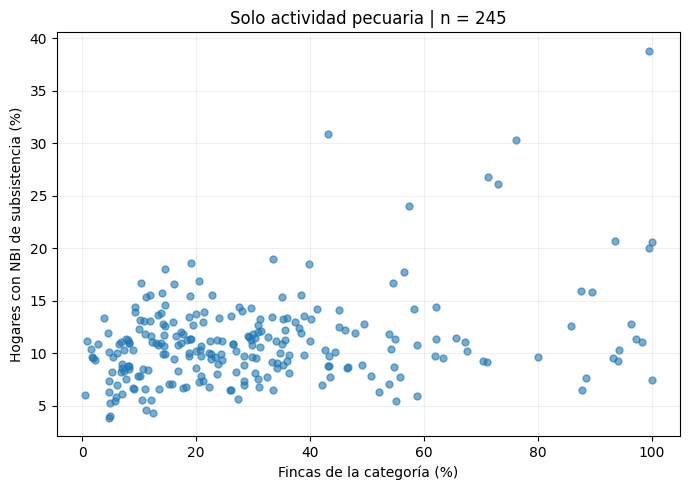

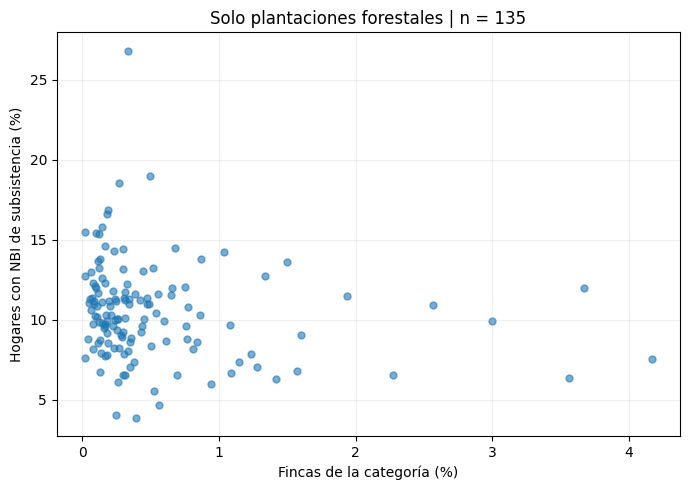

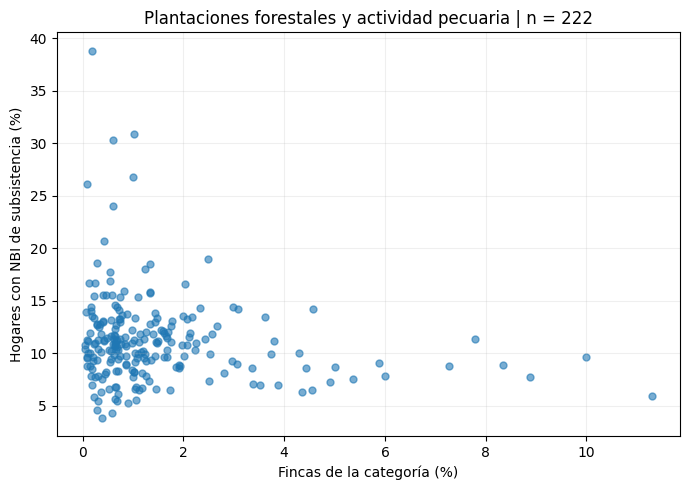

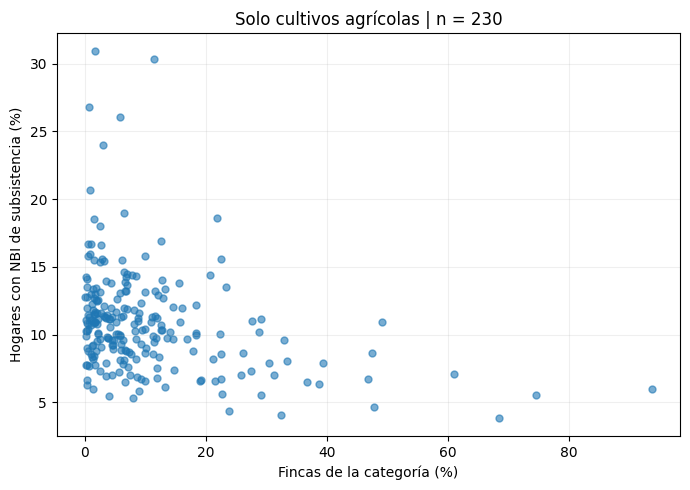

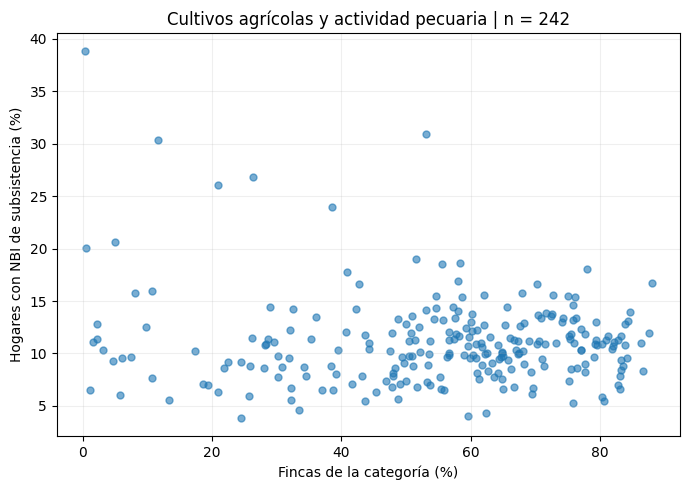

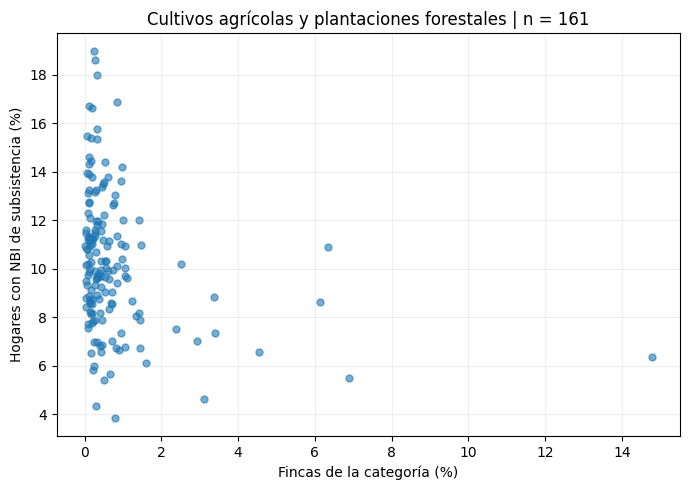

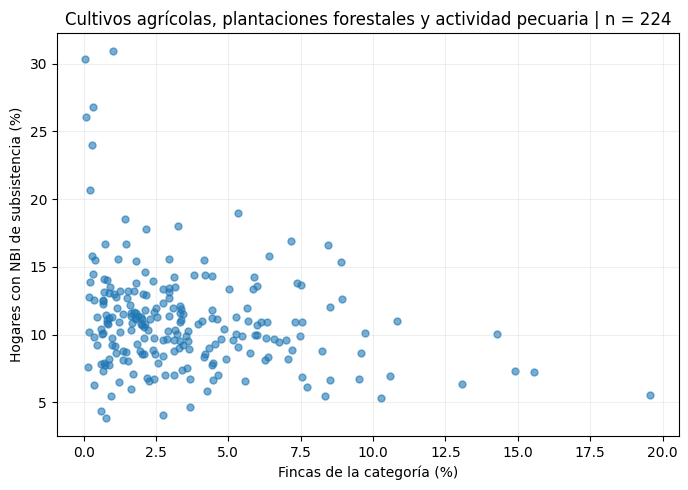

In [ ]:
import matplotlib.pyplot as plt

for activity, label in activity_labels.items():
    column = "pct_farms_" + activity

    pair = analysis[
        [column, "nbi_subsistence_pct"]
    ].dropna()

    fig, ax = plt.subplots(figsize=(7, 5))

    ax.scatter(
        pair[column],
        pair["nbi_subsistence_pct"],
        alpha=0.6,
        s=25
    )

    ax.set_title(label + " | n = " + str(len(pair)))
    ax.set_xlabel("Fincas de la categoría (%)")
    ax.set_ylabel("Hogares con NBI de subsistencia (%)")
    ax.grid(alpha=0.2)

    fig.tight_layout()

    fig.savefig(
        "scatter_" + activity + ".png",
        dpi=200
    )

    plt.show()
    plt.close(fig)

In [ ]:
display(
    analysis[
        [
            "department_nbi",
            "district_nbi",
            "nbi_subsistence_pct",
            "farms_total"
        ]
    ].nlargest(10, "nbi_subsistence_pct")
)

,department_nbi,district_nbi,nbi_subsistence_pct,farms_total
237,Presidente Hayes,Puerto Pinasco,38.836542,541.0
72,Canindeyú,Itanará,30.923695,294.0
36,Boquerón,Mariscal José Félix Estigarribia,30.363423,1821.0
112,Concepción,Paso Barreto,26.827243,300.0
239,Presidente Hayes,Tte. 1° Manuel Irala Fernández,26.095476,1285.0
113,Concepción,Paso Horqueta,24.003583,1003.0
3,Alto Paraguay,Puerto Casado,20.663114,468.0
233,Presidente Hayes,General José María Bruguez,20.606827,382.0
238,Presidente Hayes,Teniente Esteban Martínez,20.078227,191.0
217,Paraguarí,Escobar,18.982387,804.0


In [ ]:
import statsmodels.formula.api as smf

livestock_data = analysis[
    ["nbi_subsistence_pct", "pct_farms_livestock_only"]
].dropna()

livestock_model = smf.ols(
    "nbi_subsistence_pct ~ pct_farms_livestock_only",
    data=livestock_data
).fit(cov_type="HC3")

print(livestock_model.summary())

                             OLS Regression Results                            
Dep. Variable:     nbi_subsistence_pct   R-squared:                       0.107
Model:                             OLS   Adj. R-squared:                  0.103
Method:                  Least Squares   F-statistic:                     10.50
Date:                 Wed, 21 Oct 2026   Prob (F-statistic):            0.00136
Time:                         18:45:27   Log-Likelihood:                -691.78
No. Observations:                  245   AIC:                             1388.
Df Residuals:                      243   BIC:                             1395.
Df Model:                            1                                         
Covariance Type:                   HC3                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept     

In [ ]:
crops_data = analysis[
    ["nbi_subsistence_pct", "pct_farms_crops_only"]
].dropna()

crops_model = smf.ols(
    "nbi_subsistence_pct ~ pct_farms_crops_only",
    data=crops_data
).fit(cov_type="HC3")

print(crops_model.summary())

                             OLS Regression Results                            
Dep. Variable:     nbi_subsistence_pct   R-squared:                       0.104
Model:                             OLS   Adj. R-squared:                  0.100
Method:                  Least Squares   F-statistic:                     42.04
Date:                 Wed, 21 Oct 2026   Prob (F-statistic):           5.47e-10
Time:                         18:45:27   Log-Likelihood:                -626.47
No. Observations:                  230   AIC:                             1257.
Df Residuals:                      228   BIC:                             1264.
Df Model:                            1                                         
Covariance Type:                   HC3                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept             

In [ ]:
common_data = analysis[
    [
        "nbi_subsistence_pct",
        "pct_farms_crops_only",
        "pct_farms_livestock_only"
    ]
].dropna()

print("Distritos en la muestra común:", len(common_data))

Distritos en la muestra común: 230


In [ ]:
crops_common = smf.ols(
    "nbi_subsistence_pct ~ pct_farms_crops_only",
    data=common_data
).fit(cov_type="HC3")

livestock_common = smf.ols(
    "nbi_subsistence_pct ~ pct_farms_livestock_only",
    data=common_data
).fit(cov_type="HC3")

joint_model = smf.ols(
    "nbi_subsistence_pct ~ pct_farms_crops_only + pct_farms_livestock_only",
    data=common_data
).fit(cov_type="HC3")

print(joint_model.summary())

                             OLS Regression Results                            
Dep. Variable:     nbi_subsistence_pct   R-squared:                       0.138
Model:                             OLS   Adj. R-squared:                  0.131
Method:                  Least Squares   F-statistic:                     23.49
Date:                 Wed, 21 Oct 2026   Prob (F-statistic):           5.33e-10
Time:                         18:45:27   Log-Likelihood:                -622.02
No. Observations:                  230   AIC:                             1250.
Df Residuals:                      227   BIC:                             1260.
Df Model:                            2                                         
Covariance Type:                   HC3                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept     

In [ ]:
model_comparison = pd.DataFrame({
    "model": ["Agrícola", "Pecuario", "Conjunto"],
    "n": [
        crops_common.nobs,
        livestock_common.nobs,
        joint_model.nobs
    ],
    "r_squared": [
        crops_common.rsquared,
        livestock_common.rsquared,
        joint_model.rsquared
    ],
    "adjusted_r_squared": [
        crops_common.rsquared_adj,
        livestock_common.rsquared_adj,
        joint_model.rsquared_adj
    ]
})

display(model_comparison.round(3))

,model,n,r_squared,adjusted_r_squared
0,Agrícola,230.0,0.104,0.100
1,Pecuario,230.0,0.080,0.076
2,Conjunto,230.0,0.138,0.131


#visualization

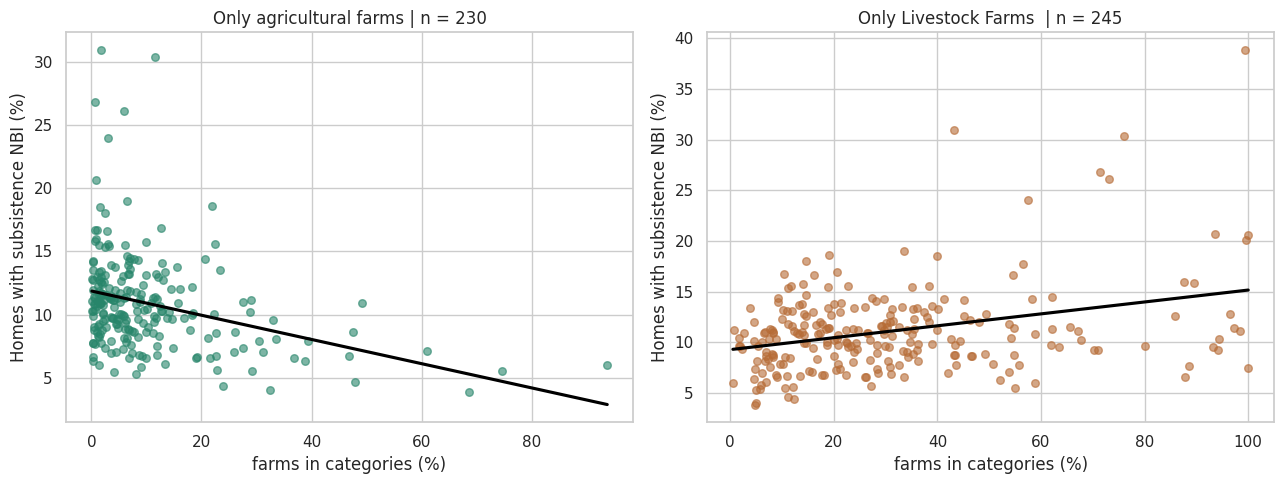

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Bring the agricultural share variables from 'analysis' into 'analysis_family' if not already present
for col in ["pct_farms_crops_only", "pct_farms_livestock_only"]:
    if col not in analysis_family.columns and col in analysis.columns:
        analysis_family = analysis_family.merge(
            analysis[["department_key", "district_key", col]],
            on=["department_key", "district_key"],
            how="left"
        )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plots = [
    ("pct_farms_crops_only", "Only agricultural farms", "#27856A"),
    ("pct_farms_livestock_only", "Only Livestock Farms ", "#B66B35")
]

for ax, (variable, title, color) in zip(axes, plots):
    data = analysis_family[
        [variable, "nbi_subsistence_pct"]
    ].dropna()

    sns.regplot(
        data=data,
        x=variable,
        y="nbi_subsistence_pct",
        ci=None,
        color=color,
        scatter_kws={"alpha": 0.6, "s": 30},
        line_kws={"color": "black"},
        ax=ax
    )

    ax.set_title(title + " | n = " + str(len(data)))
    ax.set_xlabel("farms in categories (%)")
    ax.set_ylabel("Homes with subsistence NBI (%)")

fig.tight_layout()
fig.savefig("scatter_productive_structure.png", dpi=300)
plt.show()

In [ ]:
import plotly.express as px

household_labels = {
    "uni_home": "Unipersonal",
    "comp_home": "Nuclear Complete",
    "incomp_home": "Nuclear incomplete",
    "ext_home": "Extended",
    "compound_home": "Compounded"
}

household_totals = (
    analysis_family[family_columns]
    .sum()
    .rename_axis("variable")
    .reset_index(name="households")
)

household_totals["type"] = (
    household_totals["variable"].map(household_labels)
)

fig = px.treemap(
    household_totals,
    path=["type"],
    values="households",
    color="type",
    title="Type of homes across 250 municipalities"
)

fig.update_traces(
    texttemplate="%{label}<br>%{value:,.0f} hogares<br>%{percentRoot:.1%}",
    hovertemplate="%{label}<br>Hogares: %{value:,.0f}<extra></extra>"
)

fig.update_layout(
    margin=dict(t=60, l=10, r=10, b=10)
)

fig.show()
fig.write_html("treemap_household_types.html")

In [ ]:
treemap_data = analysis_family.copy()

fig = px.treemap(
    treemap_data,
    path=["district"],
    values="nbi_subsistence_pct",
    color="nbi_subsistence_pct",
    color_continuous_scale="YlOrRd",
    custom_data=["department", "total_homes", "homesnbisubs"],
    title="District-level NBI subsistence rates, Paraguay, 2022"
)

fig.update_traces(
    texttemplate="%{label}<br>%{value:.1f}%",
    hovertemplate=(
        "<b>%{label}</b><br>"
        "Department: %{customdata[0]}<br>"
        "NBI subsistence: %{value:.2f}%<br>"
        "Total households: %{customdata[1]:,.0f}<br>"
        "Households with NBI subsistence: %{customdata[2]:,.0f}"
        "<extra></extra>"
    )
)

fig.update_layout(
    height=750,
    coloraxis_colorbar_title="NBI subsistence (%)",
    margin=dict(t=70, l=10, r=10, b=10)
)

fig.show()
fig.write_html("district_nbi_subsistence_treemap.html")

In [ ]:
!apt-get install -y gdal-bin python3-gdal
!pip install geopandas mapclassify fiona pyproj shapely

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
gdal-bin is already the newest version (3.8.4+dfsg-3ubuntu3).
python3-gdal is already the newest version (3.8.4+dfsg-3ubuntu3).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [ ]:
import zipfile
from pathlib import Path
boundary_zip = Path("/content/pry_admin_boundaries.gdb.zip")
with zipfile.ZipFile(boundary_zip) as package:
    package.extractall("/content/paraguay_boundaries")

In [ ]:
import geopandas as gpd

gdb_folders = list(
    Path("/content/paraguay_boundaries").rglob("*.gdb")
)

print("Geodatabases found:", gdb_folders)

assert len(gdb_folders) == 1, "Review the geodatabase folders before continuing."

gdb_path = str(gdb_folders[0])

display(gpd.list_layers(gdb_path))

Geodatabases found: [PosixPath('/content/paraguay_boundaries/pry_admin_boundaries.gdb')]


,name,geometry_type
0,pry_admin0,MultiPolygon
1,pry_admin1,MultiPolygon
2,pry_admin2,MultiPolygon
3,pry_admin3,MultiPolygon
4,pry_admin4,MultiPolygon
5,pry_admincapitals,Point
6,pry_adminpoints,Point


In [ ]:
districts_map = gpd.read_file(
    gdb_path,
    layer="pry_admin2"
)

print("Geographic features:", len(districts_map))
print("Coordinate reference system:", districts_map.crs)
print("Columns:", districts_map.columns.tolist())

display(
    districts_map.drop(columns="geometry").head(10)
)

Geographic features: 263
Coordinate reference system: EPSG:4326
Columns: ['adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'area_sqkm', 'valid_on', 'valid_to', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'starea__', 'stlength__', 'geometry']


,adm2_name,adm2_name1,adm2_name2,adm2_name3,adm2_pcode,adm1_name,adm1_name1,adm1_name2,adm1_name3,adm1_pcode,...,area_sqkm,valid_on,valid_to,version,lang,lang1,lang2,lang3,starea__,stlength__
0,Asunción,None,None,None,PY0000,Asunción,None,None,None,PY00,...,128.693902,2026-07-29,NaT,v01,es,None,None,None,0.011535,0.560602
1,Concepción,None,None,None,PY0101,Concepción,None,None,None,PY01,...,444.691608,2026-07-29,NaT,v01,es,None,None,None,0.039277,1.382861
2,Belén,None,None,None,PY0102,Concepción,None,None,None,PY01,...,209.585456,2026-07-29,NaT,v01,es,None,None,None,0.018517,0.853762
3,Horqueta,None,None,None,PY0103,Concepción,None,None,None,PY01,...,1300.755325,2026-07-29,NaT,v01,es,None,None,None,0.114823,2.011733
4,Loreto,None,None,None,PY0104,Concepción,None,None,None,PY01,...,771.404333,2026-07-29,NaT,v01,es,None,None,None,0.068033,1.847367
5,San Carlos del Apa,None,None,None,PY0105,Concepción,None,None,None,PY01,...,1644.036372,2026-07-29,NaT,v01,es,None,None,None,0.144157,2.425632
6,San Lázaro,None,None,None,PY0106,Concepción,None,None,None,PY01,...,1188.297918,2026-07-29,NaT,v01,es,None,None,None,0.104103,2.065299
7,Yby Yaú,None,None,None,PY0107,Concepción,None,None,None,PY01,...,2191.061980,2026-07-29,NaT,v01,es,None,None,None,0.192976,2.681978
8,Azote'y,None,None,None,PY0108,Concepción,None,None,None,PY01,...,721.407289,2026-07-29,NaT,v01,es,None,None,None,0.063689,1.786283
9,Sargento José Félix López,None,None,None,PY0109,Concepción,None,None,None,PY01,...,2257.718037,2026-07-29,NaT,v01,es,None,None,None,0.198189,2.452753


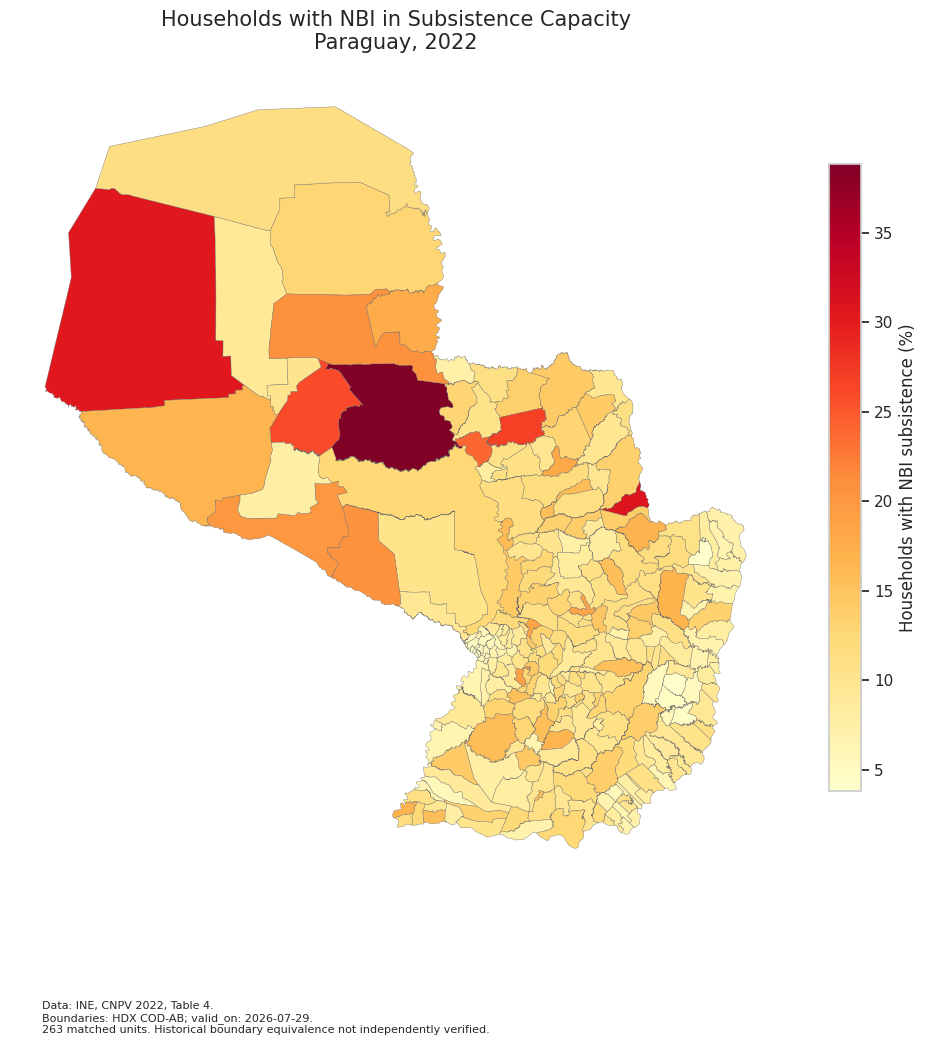

In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd

# Define normalize_name to ensure keys match correctly
import unicodedata

def normalize_name(text):
    if not isinstance(text, str):
        return ""
    text = text.lower().strip()
    text = text.replace("’", "'")
    text = text.replace("‘", "'")
    text = unicodedata.normalize("NFKD", text)
    text = "".join(
        character for character in text
        if not unicodedata.combining(character)
    )
    text = " ".join(text.split())
    return text

# 1. Create standardized keys in your district shapefile 'districts_map'
districts_map["department_key"] = districts_map["adm1_name"].apply(normalize_name)
districts_map["district_key"] = districts_map["adm2_name"].apply(normalize_name)

# 2. Extract NBI subsistence rate data from your family dataset
nbi_map_data = analysis_family[["department_key", "district_key", "nbi_subsistence_pct"]].copy()

# 3. Merge the boundaries with the NBI data to create 'nbi_map'
nbi_map = districts_map.merge(
    nbi_map_data,
    on=["department_key", "district_key"],
    how="left"
)

# Use a projected coordinate system for the static map.
map_plot = nbi_map.to_crs(epsg=5880)

fig, ax = plt.subplots(figsize=(10, 11))

map_plot.plot(
    column="nbi_subsistence_pct",
    cmap="YlOrRd",
    edgecolor="#666666",
    linewidth=0.25,
    legend=True,
    legend_kwds={
        "label": "Households with NBI subsistence (%)",
        "shrink": 0.65
    },
    missing_kwds={
        "color": "lightgrey",
        "label": "No data"
    },
    ax=ax
)

ax.set_title(
    "Households with NBI in Subsistence Capacity\n"
    "Paraguay, 2022",
    fontsize=15,
    pad=15
)

ax.set_axis_off()

fig.text(
    0.05,
    0.04,
    "Data: INE, CNPV 2022, Table 4.\n"
    "Boundaries: HDX COD-AB; valid_on: 2026-07-29.\n"
    "263 matched units. Historical boundary equivalence not independently verified.",
    fontsize=8
)

fig.tight_layout(rect=[0, 0.09, 1, 1])

fig.savefig(
    "paraguay_nbi_subsistence_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

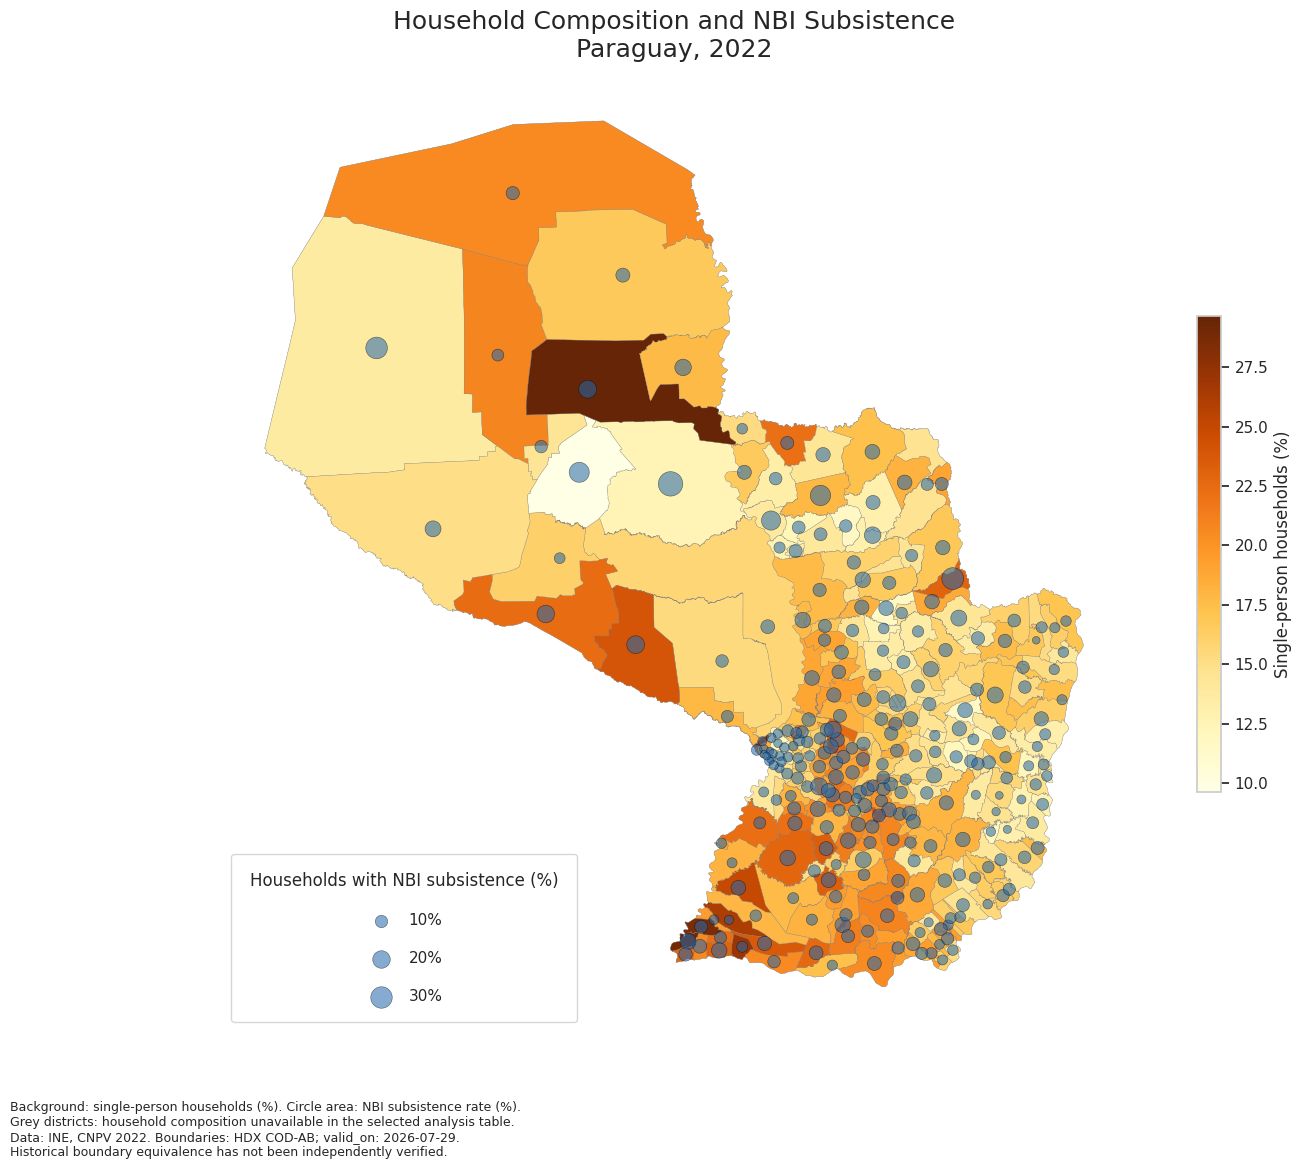

In [ ]:
import matplotlib.pyplot as plt

# --- 1. ADD HOUSEHOLD COMPOSITION TO THE MAP ---
# Select only the columns needed for this visualization.
household_map_data = analysis_family[
    ["department_key", "district_key", "pct_uni_home"]
].copy()

combined_map = nbi_map.merge(
    household_map_data,
    on=["department_key", "district_key"],
    how="left",
    validate="one_to_one"
)

# Project the boundaries before placing symbols.
combined_map = combined_map.to_crs(epsg=5880)

# --- 2. CONFIGURATION ---
background_variable = "pct_uni_home"
circle_variable = "nbi_subsistence_pct"

background_label = "Single-person households (%)"
circle_label = "Households with NBI subsistence (%)"

background_cmap = "YlOrBr"
circle_color = "#2166AC"
size_factor = 8

title = (
    "Household Composition and NBI Subsistence\n"
    "Paraguay, 2022"
)

output_filename = "household_composition_nbi_map.png"

# --- 3. CREATE THE FIGURE ---
fig, ax = plt.subplots(figsize=(15, 12))

# Draw all boundaries in grey first.
# Districts without background data will remain grey.
combined_map.plot(
    color="#E0E0E0",
    edgecolor="grey",
    linewidth=0.2,
    ax=ax
)

background_data = combined_map.dropna(
    subset=[background_variable]
)

background_data.plot(
    column=background_variable,
    cmap=background_cmap,
    linewidth=0.2,
    edgecolor="grey",
    ax=ax,
    legend=True,
    legend_kwds={
        "shrink": 0.5,
        "label": background_label
    }
)

# --- 4. ADD PROPORTIONAL CIRCLES ---
circle_data = combined_map.dropna(
    subset=[circle_variable]
).copy()

# Place points inside each district polygon.
circle_points = circle_data.geometry.representative_point()

ax.scatter(
    circle_points.x,
    circle_points.y,
    s=circle_data[circle_variable] * size_factor,
    color=circle_color,
    alpha=0.55,
    edgecolor="black",
    linewidth=0.4,
    zorder=3
)

# --- 5. CREATE THE CIRCLE LEGEND ---
example_values = [10, 20, 30]

legend_handles = []

for value in example_values:
    handle = ax.scatter(
        [],
        [],
        s=value * size_factor,
        color=circle_color,
        alpha=0.55,
        edgecolor="black",
        linewidth=0.4,
        label=f"{value}%"
    )

    legend_handles.append(handle)

ax.legend(
    handles=legend_handles,
    title=circle_label,
    loc="lower left",
    frameon=True,
    labelspacing=1.5,
    borderpad=1.2
)

# --- 6. TITLE, SOURCE NOTE, AND EXPORT ---
ax.set_title(title, fontsize=18, pad=15)
ax.set_axis_off()

fig.text(
    0.05,
    0.03,
    "Background: single-person households (%). "
    "Circle area: NBI subsistence rate (%).\n"
    "Grey districts: household composition unavailable in the selected analysis table.\n"
    "Data: INE, CNPV 2022. Boundaries: HDX COD-AB; valid_on: 2026-07-29.\n"
    "Historical boundary equivalence has not been independently verified.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.12, 1, 1])

fig.savefig(
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

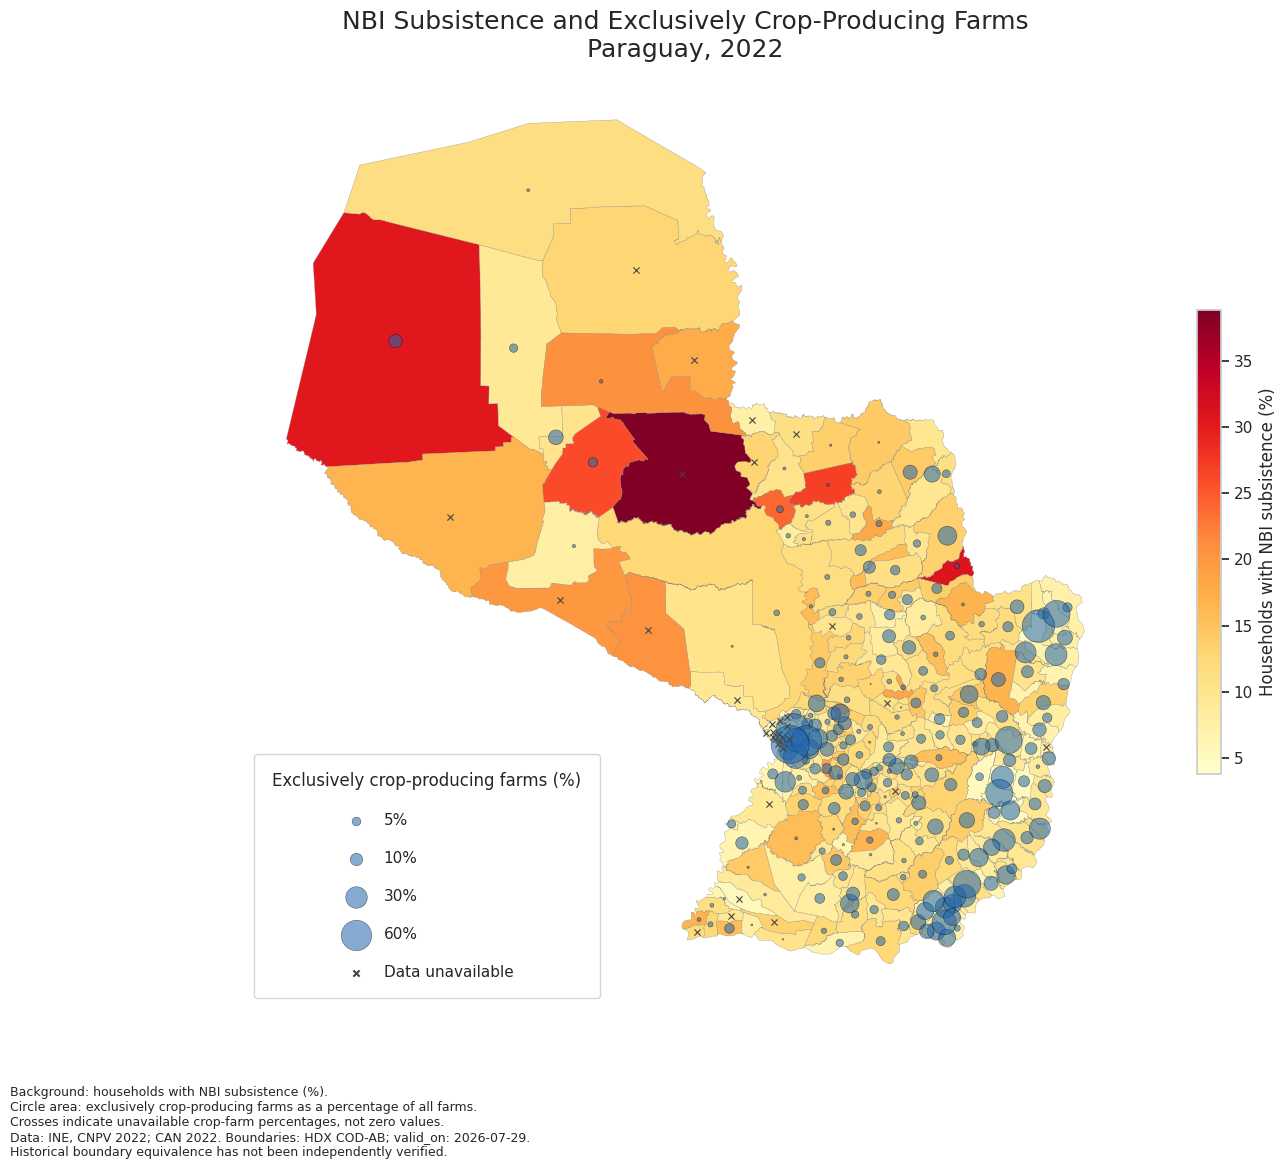

In [ ]:
import matplotlib.pyplot as plt

# --- 1. ADD THE AGRICULTURAL VARIABLE ---
agriculture_data = analysis_family[
    [
        "department_key",
        "district_key",
        "pct_farms_crops_only"
    ]
].copy()

agriculture_map = nbi_map.merge(
    agriculture_data,
    on=["department_key", "district_key"],
    how="left",
    validate="one_to_one"
)

agriculture_map = agriculture_map.to_crs(epsg=5880)

# --- 2. CONFIGURATION ---
size_factor = 8
circle_color = "#2166AC"

output_filename = "nbi_crop_farms_map.png"

fig, ax = plt.subplots(figsize=(15, 12))

# --- 3. BACKGROUND: NBI SUBSISTENCE ---
agriculture_map.plot(
    column="nbi_subsistence_pct",
    cmap="YlOrRd",
    edgecolor="grey",
    linewidth=0.2,
    legend=True,
    legend_kwds={
        "shrink": 0.5,
        "label": "Households with NBI subsistence (%)"
    },
    ax=ax
)

# --- 4. CIRCLES: EXCLUSIVELY CROP-PRODUCING FARMS ---
circle_data = agriculture_map.dropna(
    subset=["pct_farms_crops_only"]
).copy()

circle_points = circle_data.geometry.representative_point()

ax.scatter(
    circle_points.x,
    circle_points.y,
    s=circle_data["pct_farms_crops_only"] * size_factor,
    color=circle_color,
    alpha=0.55,
    edgecolor="black",
    linewidth=0.4,
    zorder=3
)

# --- 5. MARK DISTRICTS WITH MISSING AGRICULTURAL DATA ---
missing_data = agriculture_map.loc[
    agriculture_map["pct_farms_crops_only"].isna()
]

missing_points = missing_data.geometry.representative_point()

ax.scatter(
    missing_points.x,
    missing_points.y,
    marker="x",
    s=20,
    color="#444444",
    linewidth=0.8,
    label="Crop-farm percentage unavailable",
    zorder=4
)

# --- 6. SYMBOL LEGEND ---
legend_handles = []

for value in [5,10, 30, 60]:
    handle = ax.scatter(
        [],
        [],
        s=value * size_factor,
        color=circle_color,
        alpha=0.55,
        edgecolor="black",
        linewidth=0.4,
        label=f"{value}%"
    )

    legend_handles.append(handle)

missing_handle = ax.scatter(
    [], [],
    marker="x",
    s=20,
    color="#444444",
    label="Data unavailable"
)

legend_handles.append(missing_handle)

ax.legend(
    handles=legend_handles,
    title="Exclusively crop-producing farms (%)",
    loc="lower left",
    labelspacing=1.5,
    borderpad=1.2,
    frameon=True
)

# --- 7. TITLE AND SOURCE NOTE ---
ax.set_title(
    "NBI Subsistence and Exclusively Crop-Producing Farms\n"
    "Paraguay, 2022",
    fontsize=18,
    pad=15
)

ax.set_axis_off()

fig.text(
    0.05,
    0.03,
    "Background: households with NBI subsistence (%).\n"
    "Circle area: exclusively crop-producing farms as a percentage of all farms.\n"
    "Crosses indicate unavailable crop-farm percentages, not zero values.\n"
    "Data: INE, CNPV 2022; CAN 2022. "
    "Boundaries: HDX COD-AB; valid_on: 2026-07-29.\n"
    "Historical boundary equivalence has not been independently verified.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.14, 1, 1])

fig.savefig(
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

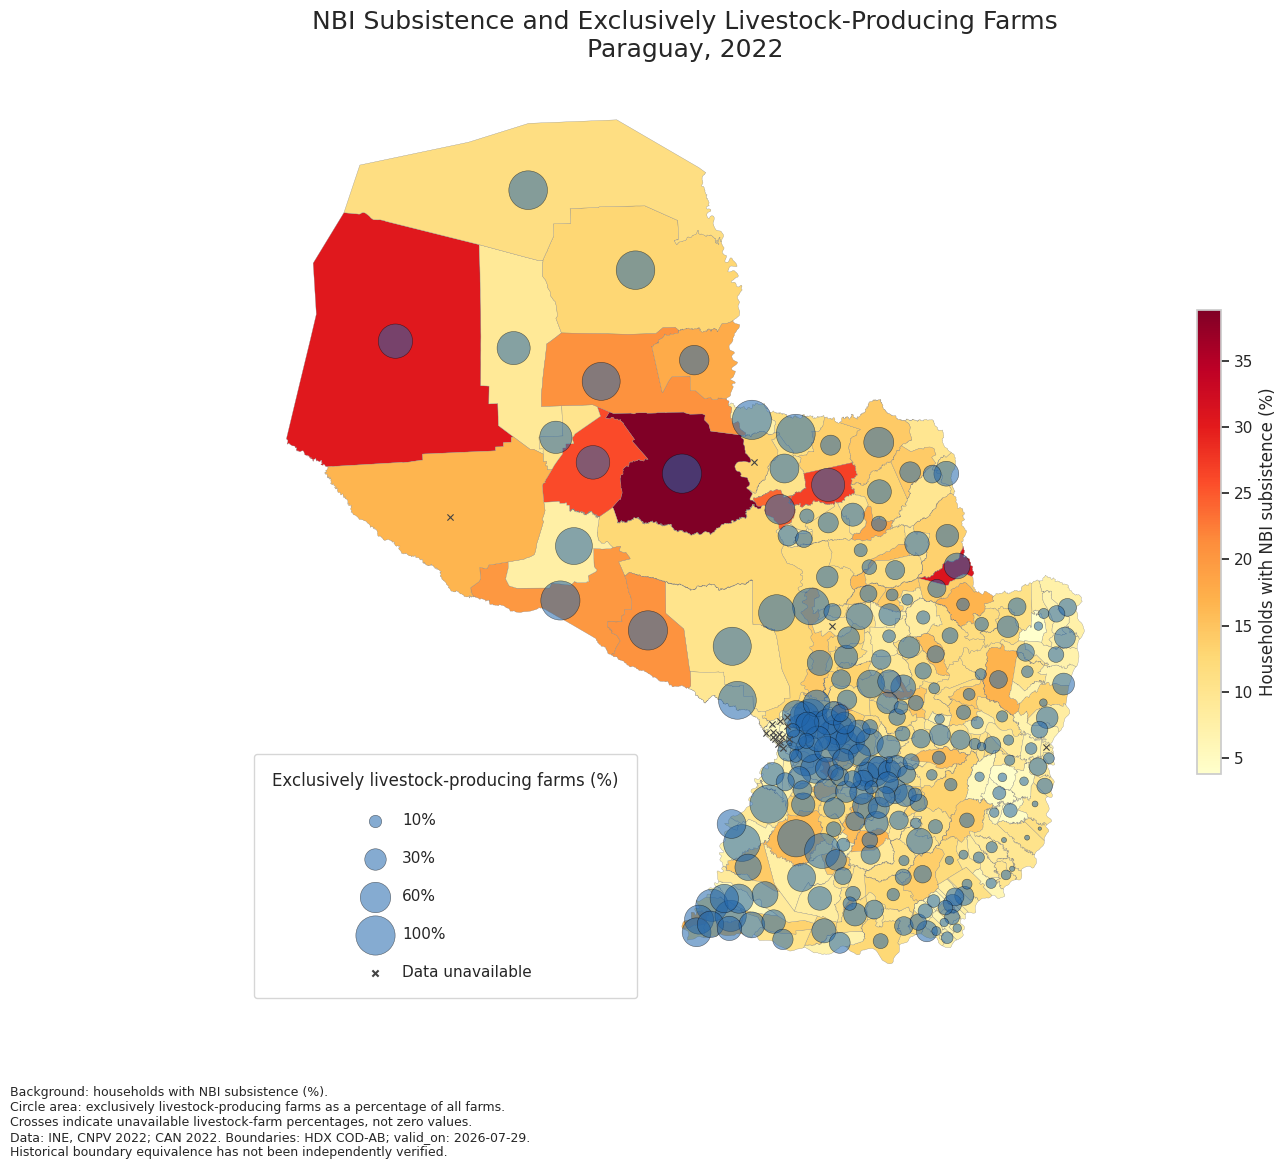

In [ ]:
import matplotlib.pyplot as plt

# --- 1. ADD THE LIVESTOCK VARIABLE ---
livestock_data = analysis_family[
    [
        "department_key",
        "district_key",
        "pct_farms_livestock_only"
    ]
].copy()

livestock_map = nbi_map.merge(
    livestock_data,
    on=["department_key", "district_key"],
    how="left",
    validate="one_to_one"
)

livestock_map = livestock_map.to_crs(epsg=5880)

# --- 2. CONFIGURATION ---
size_factor = 8
circle_color = "#2166AC"
output_filename = "nbi_livestock_farms_map.png"

fig, ax = plt.subplots(figsize=(15, 12))

# --- 3. BACKGROUND: NBI SUBSISTENCE ---
livestock_map.plot(
    column="nbi_subsistence_pct",
    cmap="YlOrRd",
    edgecolor="grey",
    linewidth=0.2,
    legend=True,
    legend_kwds={
        "shrink": 0.5,
        "label": "Households with NBI subsistence (%)"
    },
    ax=ax
)

# --- 4. CIRCLES: EXCLUSIVELY LIVESTOCK-PRODUCING FARMS ---
circle_data = livestock_map.dropna(
    subset=["pct_farms_livestock_only"]
).copy()

circle_points = circle_data.geometry.representative_point()

# Draw larger circles first so smaller circles remain visible.
circle_data["point_x"] = circle_points.x
circle_data["point_y"] = circle_points.y

circle_data = circle_data.sort_values(
    "pct_farms_livestock_only",
    ascending=False
)

ax.scatter(
    circle_data["point_x"],
    circle_data["point_y"],
    s=circle_data["pct_farms_livestock_only"] * size_factor,
    color=circle_color,
    alpha=0.55,
    edgecolor="black",
    linewidth=0.4,
    zorder=3
)

# --- 5. MARK MISSING LIVESTOCK DATA ---
missing_data = livestock_map.loc[
    livestock_map["pct_farms_livestock_only"].isna()
]

missing_points = missing_data.geometry.representative_point()

ax.scatter(
    missing_points.x,
    missing_points.y,
    marker="x",
    s=20,
    color="#444444",
    linewidth=0.8,
    zorder=4
)

# --- 6. SYMBOL LEGEND ---
legend_handles = []

for value in [10, 30, 60, 100]:
    handle = ax.scatter(
        [],
        [],
        s=value * size_factor,
        color=circle_color,
        alpha=0.55,
        edgecolor="black",
        linewidth=0.4,
        label=f"{value}%"
    )

    legend_handles.append(handle)

legend_handles.append(
    ax.scatter(
        [], [],
        marker="x",
        s=20,
        color="#444444",
        label="Data unavailable"
    )
)

ax.legend(
    handles=legend_handles,
    title="Exclusively livestock-producing farms (%)",
    loc="lower left",
    labelspacing=1.5,
    borderpad=1.2,
    frameon=True
)

# --- 7. TITLE, NOTES, AND EXPORT ---
ax.set_title(
    "NBI Subsistence and Exclusively Livestock-Producing Farms\n"
    "Paraguay, 2022",
    fontsize=18,
    pad=15
)

ax.set_axis_off()

fig.text(
    0.05,
    0.03,
    "Background: households with NBI subsistence (%).\n"
    "Circle area: exclusively livestock-producing farms as a percentage of all farms.\n"
    "Crosses indicate unavailable livestock-farm percentages, not zero values.\n"
    "Data: INE, CNPV 2022; CAN 2022. "
    "Boundaries: HDX COD-AB; valid_on: 2026-07-29.\n"
    "Historical boundary equivalence has not been independently verified.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.14, 1, 1])

fig.savefig(
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
print("Map districts:", len(agriculture_map))

print(
    "Districts with crop-only percentages:",
    agriculture_map["pct_farms_crops_only"].notna().sum()
)

print(
    "Districts shown with crosses:",
    agriculture_map["pct_farms_crops_only"].isna().sum()
)

print(
    "Available crop-only percentages before the map join:",
    analysis_family["pct_farms_crops_only"].notna().sum()
)

Map districts: 263
Districts with crop-only percentages: 230
Districts shown with crosses: 33
Available crop-only percentages before the map join: 230


In [ ]:
display(
    agriculture_map.loc[
        agriculture_map["pct_farms_crops_only"].isna(),
        ["adm1_name", "adm2_name"]
    ].sort_values(["adm1_name", "adm2_name"])
)

,adm1_name,adm2_name
262,Alto Paraguay,Carmelo Peralta
259,Alto Paraguay,Fuerte Olimpo
166,Alto Paraná,Ciudad del Este
0,Asunción,Asunción
258,Boquerón,Boquerón
93,Caaguazú,Simón Bolivar
189,Central,Capiatá
190,Central,Fernando de la Mora
194,Central,Lambaré
195,Central,Limpio


In [ ]:
print(
    "Available percentages on the map:",
    agriculture_map["pct_farms_crops_only"].notna().sum()
)

print(
    "Crosses on the map:",
    agriculture_map["pct_farms_crops_only"].isna().sum()
)

Available percentages on the map: 230
Crosses on the map: 33


In [215]:
%%capture

import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
import json

# Forzar el renderizador optimizado para evitar bloqueos de seguridad en Google Colab
pio.renderers.default = 'colab'

# --- 1. JOIN THE PRODUCTIVE VARIABLES TO THE BOUNDARIES ---
productive_variables = analysis_family[
    [
        "department_key",
        "district_key",
        "pct_farms_crops_only",
        "pct_farms_livestock_only"
    ]
].copy()

interactive_productive = nbi_map.merge(
    productive_variables,
    on=["department_key", "district_key"],
    how="left",
    validate="one_to_one"
)

# Calculate interior points in projected coordinates for placing symbols.
projected = interactive_productive.to_crs(epsg=5880)
points = projected.geometry.representative_point().to_crs(epsg=4326)

interactive_productive["longitude"] = points.x
interactive_productive["latitude"] = points.y

# Convert any non-serializable Timestamp columns to strings to prevent JSON serialization errors
for col in interactive_productive.columns:
    if interactive_productive[col].dtype == "datetime64[ns]" or "datetime" in str(interactive_productive[col].dtype):
        interactive_productive[col] = interactive_productive[col].dt.strftime("%Y-%m-%d")
    elif hasattr(interactive_productive[col], "dt"):
        interactive_productive[col] = interactive_productive[col].astype(str)

# Also explicitly stringify known boundary date columns just in case
for date_col in ["valid_on", "valid_to"]:
    if date_col in interactive_productive.columns:
        interactive_productive[date_col] = interactive_productive[date_col].astype(str)

# Convert GeoDataFrame geometry to GeoJSON for Plotly
geojson_dict = json.loads(interactive_productive.to_json())

# Create the base interactive choropleth map using Plotly Express
fig_base = px.choropleth_map(
    interactive_productive,
    geojson=geojson_dict,
    locations=interactive_productive.index,
    color="nbi_subsistence_pct",
    color_continuous_scale="YlOrRd",
    map_style="open-street-map",
    zoom=5.5,
    center={"lat": -23.4, "lon": -58.4},
    opacity=0.6,
    labels={"nbi_subsistence_pct": "NBI Subsistence (%)"},
    custom_data=["adm2_name", "adm1_name", "nbi_subsistence_pct"]
)

# Update hover template of the base choropleth map
fig_base.update_traces(
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Department: %{customdata[1]}<br>"
        "NBI subsistence: %{customdata[2]:.2f}%<br>"
        "<extra></extra>"
    )
)

# Create our figure structure from the base map
productive_fig = go.Figure(fig_base)

# --- 2. ADD AGRICULTURAL AND LIVESTOCK CIRCLES ---
layers = [
    (
        "pct_farms_crops_only",
        "Exclusively crop-producing farms",
        "#2166AC"
    ),
    (
        "pct_farms_livestock_only",
        "Exclusively livestock-producing farms",
        "#238B45"
    )
]

for variable, label, color in layers:
    available = interactive_productive.dropna(subset=[variable])

    productive_fig.add_trace(
        go.Scattermap(
            lon=available["longitude"],
            lat=available["latitude"],
            mode="markers",
            name=label,
            visible=False,
            customdata=available[
                ["adm2_name", "adm1_name", variable]
            ].to_numpy(),
            marker=dict(
                size=available[variable],
                sizemode="area",
                sizeref=2 * 100 / (35 ** 2),
                color=color,
                opacity=0.75
            ),
            hovertemplate=(
                "<b>%{customdata[0]}</b><br>"
                "Department: %{customdata[1]}<br>"
                + label + ": %{customdata[2]:.2f}%"
                "<extra></extra>"
            )
        )
    )

# --- 3. ADD LAYER BUTTONS ---
# Trace order: 0 (NBI background), 1 (agricultural circles), 2 (livestock circles)
productive_fig.update_layout(
    title="NBI Subsistence and Farm Composition — Paraguay, 2022",
    updatemenus=[
        dict(
            type="buttons",
            direction="right",
            x=0,
            y=1.08,
            buttons=[
                dict(
                    label="NBI only",
                    method="update",
                    args=[{"visible": [True, False, False]}]
                ),
                dict(
                    label="Crop-only farms",
                    method="update",
                    args=[{"visible": [True, True, False]}]
                ),
                dict(
                    label="Livestock-only farms",
                    method="update",
                    args=[{"visible": [True, False, True]}]
                )
            ]
        )
    ],
    margin=dict(t=130, b=80),
    annotations=[
        dict(
            text=(
                "Background: NBI subsistence (%). "
                "Circle area: farms in the selected category (%).<br>"
                "Missing percentages are omitted; no circle does not establish zero.<br>"
                "Data: CNPV/CAN 2022. HDX boundaries valid_on: 2026-07-29; "
                "historical equivalence not verified."
            ),
            x=0,
            y=-0.06,
            xref="paper",
            yref="paper",
            showarrow=False,
            align="left",
            font=dict(size=10)
        )
    ]
)

productive_fig.show(config={"scrollZoom": True})